# Clase completa de NLP: EDA, limpieza y análisis de sentimiento con Logistic Regression

**Dataset:** `imdb_movie_reviews_large.csv`  
**Problema:** clasificación binaria de sentimiento en reseñas de películas.  
**Modelo único:** Logistic Regression.  
**Representaciones:** One-Hot / Binary Encoding, Bag of Words y TF-IDF.

---

## Objetivos de aprendizaje

Al finalizar este notebook, el estudiante estará en capacidad de:

1. Explorar visualmente un dataset textual.
2. Identificar problemas comunes en datos de texto: ruido, stop words, palabras raras, HTML, signos, longitud variable.
3. Construir una función de normalización y limpieza de texto.
4. Transformar texto en vectores usando representaciones clásicas.
5. Entrenar modelos de clasificación de sentimiento usando Logistic Regression.
6. Evaluar modelos con métricas de clasificación.
7. Comparar el impacto de diferentes representaciones y de la limpieza textual.
8. Interpretar errores y palabras importantes del modelo.

---

## Estructura del notebook

0. Configuración inicial  
1. NLP EDA  
2. Text Normalizing and Cleaning  
3. Sentiment Analysis con One-Hot / Binary Encoding  
4. Sentiment Analysis con Bag of Words  
5. Sentiment Analysis con TF-IDF  
6. Comparación global de resultados  
7. Interpretación del modelo  
8. Análisis de errores  
9. Conclusiones

> **Versión para estudiantes (sin soluciones):** las celdas marcadas `TODO` son actividades para completar en clase. Las celdas de código no incluyen resultados precalculados. Ejecute las celdas progresivamente; los bloques con `NotImplementedError` requieren implementación antes de continuar.


# 0. Configuración inicial

En esta sección preparamos las importaciones y completaremos en clase la carga del dataset y las funciones auxiliares.

En un proyecto real de NLP, esta etapa es importante porque permite que todo el pipeline sea reproducible.  
Un pipeline reproducible debe dejar claro:

- Qué datos se usan.
- Qué columnas contienen el texto y la etiqueta.
- Cómo se divide el dataset en entrenamiento y prueba.
- Qué semilla aleatoria se usa.
- Qué métricas se van a reportar.

In [1]:
# ============================================================
# 0.1 Imports generales
# ============================================================

import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 160)

In [2]:
# TODO: Defina DATA_PATH con la ruta del CSV que se usará en clase.
# Pista: confirme el nombre real del archivo antes de leerlo.
DATA_PATH = "imdb_movie_reviews_large.csv"  # Reemplace con la ruta correcta del archivo CSV
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"No se encontró '{DATA_PATH}'. "
        "Coloque el archivo en la misma carpeta del notebook."
    )

In [3]:
# TODO: Cargue el archivo CSV en un DataFrame llamado df usando pandas.
df = pd.read_csv(DATA_PATH)

In [4]:
# TODO: Muestre las primeras 10 filas del dataset.
df.head(10)

,review,sentiment
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,1
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,0
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,1
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,1
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,0
5,Terrible waste of two hours. The {element} was inferior and the {element} was painful to listen to.,0
6,Outstanding character development and brilliant screenplay. This is how movies should be made.,1
7,Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.,0
8,Brilliant screenplay with exceptional acting. This is platinum at its finest.,1
9,Fantastic storyline and wonderful dialogue. The movie was a platinum that exceeded all expectations.,1


In [5]:
# ============================================================
# 0.3 Inspección inicial
# ============================================================

# TODO:
# - Imprima las columnas.
# - Revise los tipos de datos.
# - Revise valores nulos.
# - Revise la distribución de la variable objetivo.

print("Columnas:") 
print(df.columns)

print("Tipos de datos:") 
print(df.dtypes)

print("Valores nulos:") 
print(df.isnull().sum())

print("Distribución de la variable objetivo:") 
print(df['sentiment'].value_counts())

Columnas:
Index(['review', 'sentiment'], dtype='str')
Tipos de datos:
review         str
sentiment    int64
dtype: object
Valores nulos:
review       0
sentiment    0
dtype: int64
Distribución de la variable objetivo:
sentiment
1    1000
0    1000
Name: count, dtype: int64


## 0.4 Definición de columnas

Este dataset tiene:

- `review`: texto de la reseña.
- `sentiment`: etiqueta de sentimiento.
    - `1`: sentimiento positivo.
    - `0`: sentimiento negativo.

Vamos a crear variables estándar para que el resto del notebook sea más fácil de reutilizar.

In [6]:
# TODO: Identifique y defina TEXT_COL y LABEL_COL según el archivo.
# TODO: Cree la columna sentiment_label con etiquetas consistentes.
TEXT_COL = "review"  # columna con el texto de la reseña
LABEL_COL = "sentiment"  # columna con la etiqueta (1 = positivo, 0 = negativo)

#Validación de columnas requeridas
required_columns = {TEXT_COL, LABEL_COL}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

# Mapeo de etiquetas a nombres legibles
df["sentiment_label"] = df[LABEL_COL].map({1: "positive", 0: "negative", "0": "negative", "1": "positive"})
df[[TEXT_COL, LABEL_COL, "sentiment_label"]].head()

,review,sentiment,sentiment_label
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,1,positive
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,0,negative
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,1,positive
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,1,positive
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,0,negative


## Ejercicio 0

Responda brevemente:

1. ¿Cuántas reseñas tiene el dataset?

   **Respuesta:** Tiene 2.000 reseñas y ninguna con valores nulos.

In [7]:
# Pregunta 1: número de reseñas
print("Total de reseñas:", len(df))
print("Valores nulos:", df[[TEXT_COL, LABEL_COL]].isnull().sum().sum())

Total de reseñas: 2000
Valores nulos: 0


2. ¿Cuántas clases tiene el problema?

   **Respuesta:** Dos: positivo (`1`) y negativo (`0`). Es una clasificación binaria.

In [8]:
# Pregunta 2: número de clases
print("Número de clases:", df[LABEL_COL].nunique())
print("Clases:", sorted(df[LABEL_COL].unique().tolist()))

Número de clases: 2
Clases: [0, 1]


3. ¿El dataset está balanceado?

   **Respuesta:** Sí, hay 1.000 reseñas positivas y 1.000 negativas.

In [9]:
# Pregunta 3: balance de clases
# TODO: Calcule cuántas observaciones hay por clase.
df[LABEL_COL].value_counts().to_frame("n").assign(pct=lambda d: d["n"] / len(df) * 100)

,n,pct
sentiment,,
1,1000,50.0
0,1000,50.0


4. ¿Qué podría pasar si el dataset estuviera muy desbalanceado?

   **Respuesta:** El modelo se inclinaría por la clase mayoritaria y el accuracy dejaría de ser confiable. En la simulación de abajo, con 95 % de positivas, un modelo que siempre responde "positivo" logra 95 % de accuracy sin detectar ni una sola negativa. En ese caso habría que mirar recall y F1 por clase, y usar técnicas como `class_weight="balanced"` o remuestreo.

In [10]:
# Pregunta 4: simulación de un dataset muy desbalanceado (95 % positivo / 5 % negativo)
# y un "modelo" que siempre predice la clase mayoritaria.
y_true_sim = np.array([1] * 950 + [0] * 50)
y_pred_sim = np.ones_like(y_true_sim)

print("Accuracy:", accuracy_score(y_true_sim, y_pred_sim))
print("Recall clase negativa:", recall_score(y_true_sim, y_pred_sim, pos_label=0))
print("F1 clase negativa:", f1_score(y_true_sim, y_pred_sim, pos_label=0))

Accuracy: 0.95
Recall clase negativa: 0.0
F1 clase negativa: 0.0


# 1. NLP EDA

La exploración de datos en NLP no solo busca entender cuántas filas y columnas tenemos.  
En texto, también debemos entender:

- Longitud de los documentos.
- Palabras más frecuentes.
- Palabras poco frecuentes.
- Stop words.
- Diferencias entre clases.
- Ruido textual.
- Patrones visuales.

Esta etapa ayuda a decidir qué limpieza realizar y qué representación textual puede funcionar mejor.

In [11]:
# TODO: Calcule num_chars y num_words por reseña.
# Pista: aplique len y separe el texto en palabras.
df["num_chars"] = df[TEXT_COL].apply(len)
df["num_words"] = df[TEXT_COL].apply(lambda x: len(x.split()))
df[[TEXT_COL, "num_chars", "num_words"]].head()

,review,num_chars,num_words
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,94,14
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,111,16
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,105,17
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,91,17
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,88,14


In [12]:
# TODO: Muestre estadísticas descriptivas globales y por clase para las longitudes.
display(df[["num_chars", "num_words"]].describe())
display(df.groupby(LABEL_COL)[["num_chars", "num_words"]].describe().T)

,num_chars,num_words
count,2000.000000,2000.000000
mean,97.884500,15.222500
std,11.210308,1.895466
min,72.000000,11.000000
25%,91.000000,14.000000
50%,97.000000,15.000000
75%,104.000000,17.000000
max,143.000000,22.000000


sentiment                  0            1
num_chars count  1000.000000  1000.000000
          mean     95.102000   100.667000
          std       7.912914    13.166376
          min      72.000000    72.000000
          25%      89.000000    92.000000
          50%      96.000000    98.000000
          75%     100.000000   108.000000
          max     115.000000   143.000000
num_words count  1000.000000  1000.000000
          mean     15.057000    15.388000
          std       1.534309     2.186375
          min      12.000000    11.000000
          25%      14.000000    14.000000
          50%      15.000000    15.000000
          75%      16.000000    17.000000
          max      18.000000    22.000000

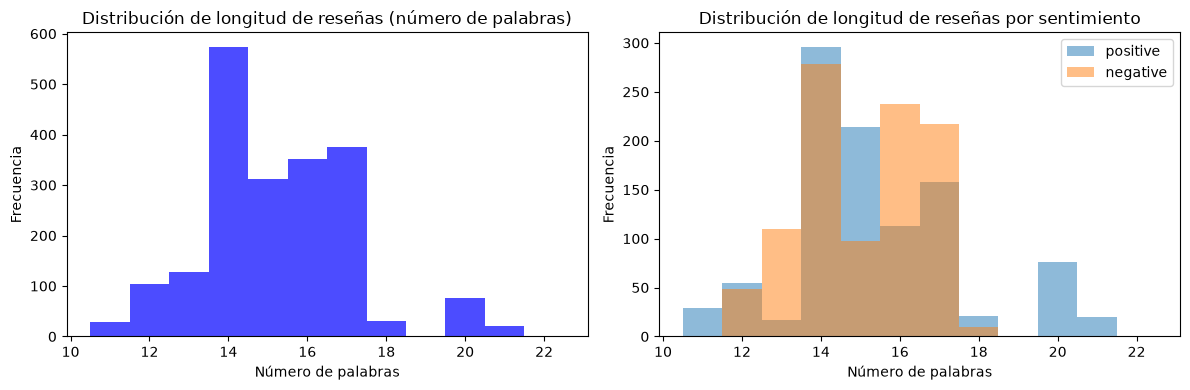

In [13]:
# TODO: Grafique histogramas de longitud de reseñas, global y por sentimiento.

# Una barra por cada número entero de palabras, con los mismos bordes en todos los histogramas.
bins = np.arange(df["num_words"].min(), df["num_words"].max() + 2) - 0.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Global
axes[0].hist(df["num_words"], bins=bins, color='blue', alpha=0.7)
axes[0].set_title("Distribución de longitud de reseñas (número de palabras)")
axes[0].set_xlabel("Número de palabras")
axes[0].set_ylabel("Frecuencia")

#Por sentimiento
for valor, nombre in [(1, "positive") , (0, "negative")]:
    subset = df[df[LABEL_COL] == valor]
    axes[1].hist(subset["num_words"], bins=bins, alpha=0.5, label=nombre)
axes[1].set_title("Distribución de longitud de reseñas por sentimiento")
axes[1].set_xlabel("Número de palabras")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

plt.tight_layout()
plt.show()

## 1.1 Palabras frecuentes

Una de las formas más simples de entender un corpus es contar palabras.

Sin embargo, hay que tener cuidado: las palabras más frecuentes suelen ser artículos, preposiciones y conectores.  
Por eso analizaremos:

1. Palabras frecuentes sin remover stop words.
2. Palabras frecuentes removiendo stop words.
3. Palabras frecuentes por clase.

In [14]:
# TODO: Implemente estas tres funciones (no están resueltas):
# - simple_tokenize(text): tokenización simple con re.findall
# - get_top_words(texts, n=20, remove_stopwords=False): contar con Counter
# - plot_top_words(top_words, title): gráfico de barras
# Pista: ENGLISH_STOP_WORDS permite filtrar stop words.

def simple_tokenize(text):
    # TODO: complete la tokenización
    return re.findall(r"[a-z']+", text.lower())

def get_top_words(texts, n=20, remove_stopwords=False):
    # TODO: complete el conteo de palabras
    vocab = Counter()
    for text in texts:
        tokens = simple_tokenize(text)
        if remove_stopwords:
            tokens = [token for token in tokens if token not in ENGLISH_STOP_WORDS]
        vocab.update(tokens)
    return vocab.most_common(n)

def plot_top_words(top_words, title):
    # TODO: complete la visualización
    words, counts = zip(*top_words)
    plt.figure(figsize=(8, 6))
    plt.barh(words, counts)
    plt.gca().invert_yaxis()  # Invertir el eje y para que la palabra más frecuente esté arriba
    plt.title(title)
    plt.xlabel("Frecuencia")
    plt.ylabel("Palabras")
    plt.show()

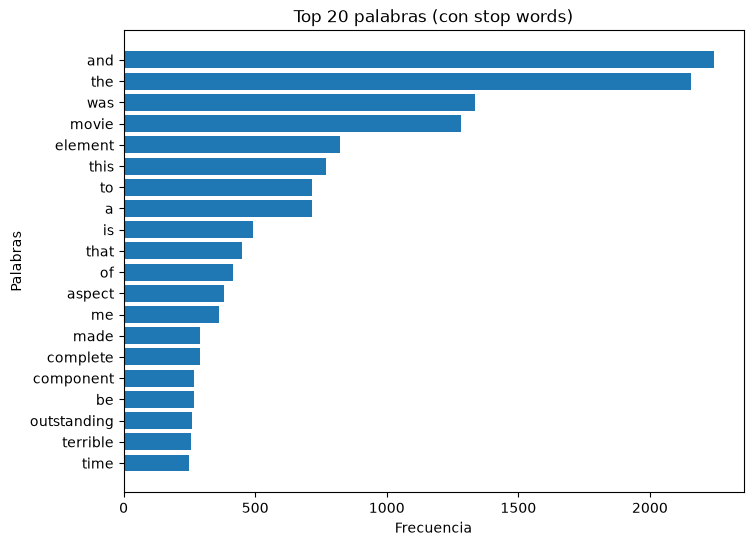

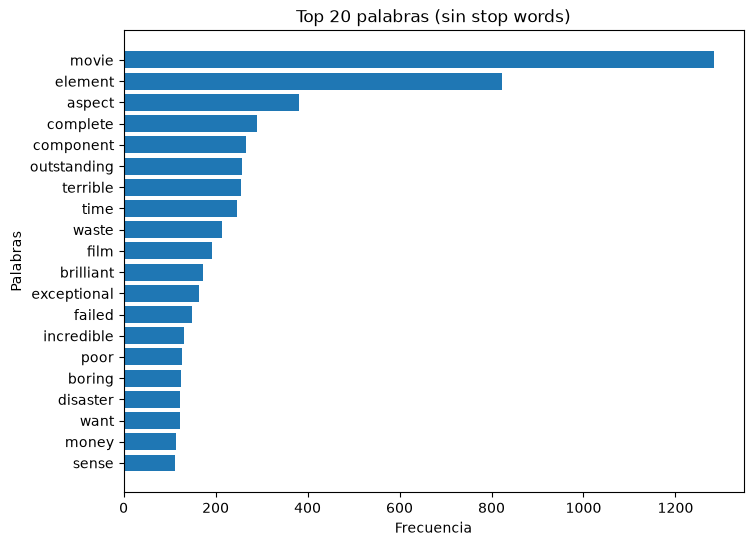

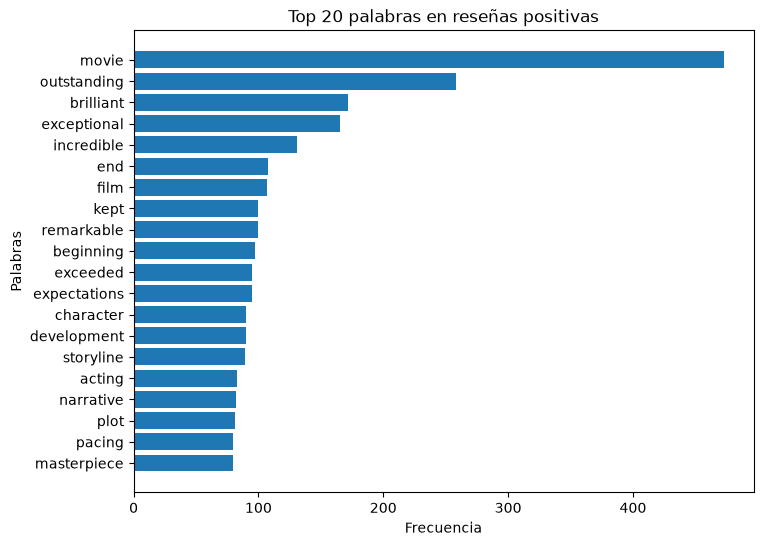

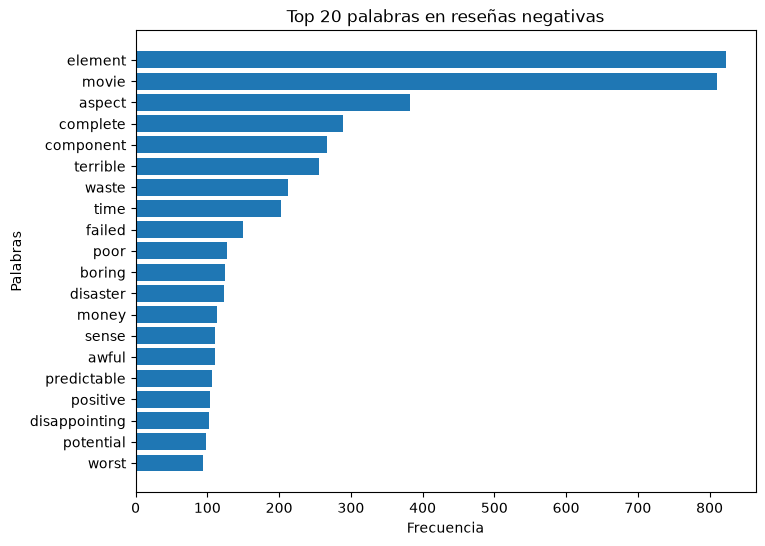

In [15]:
# TODO: Compare palabras frecuentes con/sin stop words y en reviews positivas/negativas.
# Use las funciones que implementó en la celda anterior.

# Corpus completo: con y sin stop words
plot_top_words(get_top_words(df[TEXT_COL], n=20), "Top 20 palabras (con stop words)")
plot_top_words(get_top_words(df[TEXT_COL], n=20, remove_stopwords=True), "Top 20 palabras (sin stop words)")

# Por sentimiento, sin stop words
pos_texts = df[df[LABEL_COL] == 1][TEXT_COL]
neg_texts = df[df[LABEL_COL] == 0][TEXT_COL]

plot_top_words(get_top_words(pos_texts, n=20, remove_stopwords=True), "Top 20 palabras en reseñas positivas")
plot_top_words(get_top_words(neg_texts, n=20, remove_stopwords=True), "Top 20 palabras en reseñas negativas")

## 1.2 Palabras raras

Las palabras raras son términos que aparecen muy pocas veces.  
Pueden ser útiles si representan conceptos específicos, pero también pueden ser ruido:

- Errores de escritura.
- Nombres propios.
- Tokens generados por mala limpieza.
- Símbolos mezclados con texto.
- Palabras demasiado específicas.

En modelos clásicos, un vocabulario muy grande puede hacer que las matrices sean muy dispersas.

In [16]:
# TODO: Construya el vocabulario de todo el corpus.
# Calcule palabras únicas, hapax legomena (frecuencia 1) y ejemplos.
# Pista: Counter.
vocab = Counter()
for text in df[TEXT_COL]:
    vocab.update(simple_tokenize(text))

hapax = [palabra for palabra, freq in vocab.items() if freq == 1]

print("Palabras únicas:", len(vocab))
print("Hapax legomena:", len(hapax))
print("Ejemplos:", hapax[:20])

Palabras únicas: 363
Hapax legomena: 7
Ejemplos: ['let', 'down', 'loved', 'adored', 'filmmaker', 'offended', 'uplifting']


In [17]:
# TODO: Reporte el tamaño del vocabulario, cantidad y porcentaje de palabras raras.
vocab_tamano = len(vocab)
n_raras = len(hapax)
pct_raras = (n_raras / vocab_tamano) * 100

print("Tamaño del vocabulario:", vocab_tamano)
print("Cantidad de palabras raras:", n_raras)
print("Porcentaje de palabras raras:", f"{pct_raras:.2f}%")

Tamaño del vocabulario: 363
Cantidad de palabras raras: 7
Porcentaje de palabras raras: 1.93%


count    2000.000000
mean        0.461566
std         0.068660
min         0.333333
25%         0.400000
50%         0.437500
75%         0.500000
max         0.625000
Name: stopword_ratio, dtype: float64

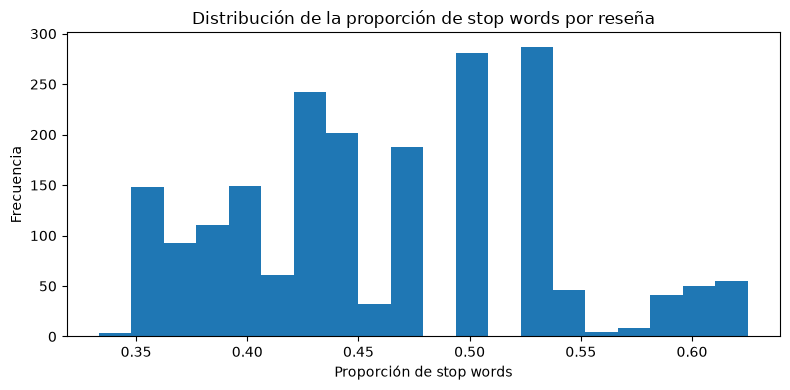

In [18]:
# TODO: Implemente stopword_ratio(text) y visualice su distribución.
# Pista: razón entre cantidad de stop words y total de tokens.
def stopword_ratio(text):
    tokens = simple_tokenize(text)
    if not tokens:  # evita dividir por cero en textos vacíos
        return 0.0
    n_stop = sum(token in ENGLISH_STOP_WORDS for token in tokens)
    return n_stop / len(tokens)

df["stopword_ratio"] = df[TEXT_COL].apply(stopword_ratio)
display(df["stopword_ratio"].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["stopword_ratio"], bins=20)
plt.title("Distribución de la proporción de stop words por reseña")
plt.xlabel("Proporción de stop words")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 1.3 Nubes de palabras

Las nubes de palabras son visualizaciones útiles para clase porque muestran de forma intuitiva qué términos dominan en el corpus.

No deben tomarse como una prueba estadística fuerte, pero ayudan a generar hipótesis.

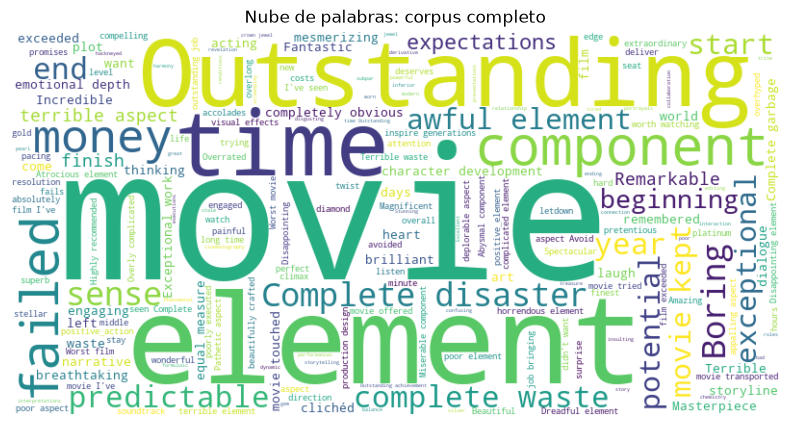

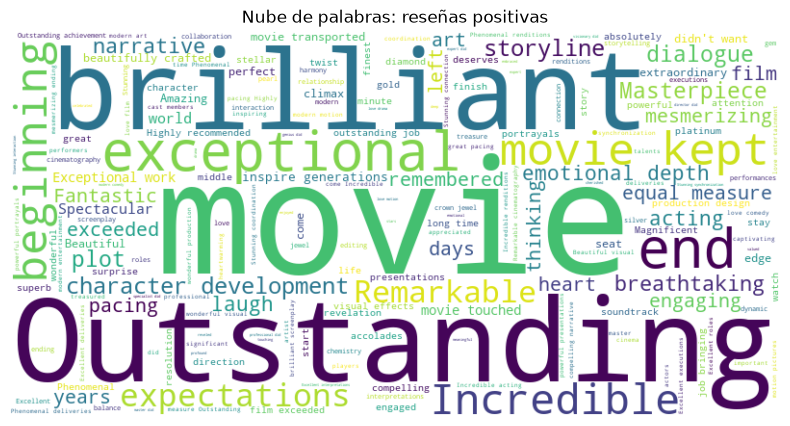

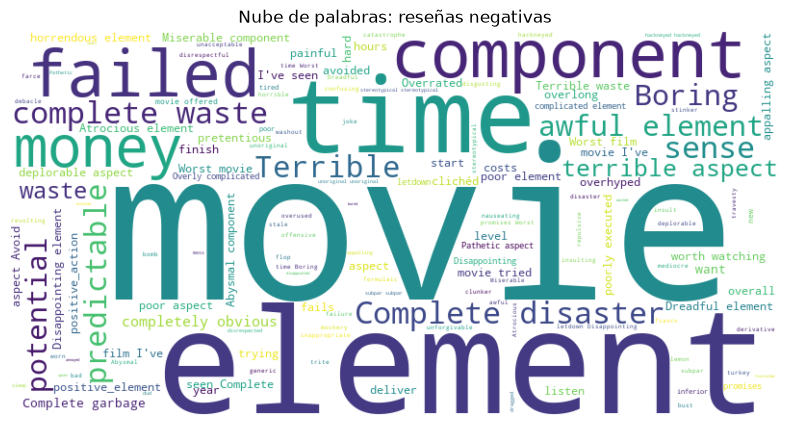

In [19]:
# TODO: Genere nubes de palabras del corpus completo, reviews positivas y negativas.
# Pista: from wordcloud import WordCloud
def plot_wordcloud(texts, title):
    texto = " ".join(texts)
    wc = WordCloud(width=800, height=400, background_color="white",
                   stopwords=ENGLISH_STOP_WORDS).generate(texto)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.show()

plot_wordcloud(df[TEXT_COL], "Nube de palabras: corpus completo")
plot_wordcloud(df[df[LABEL_COL] == 1][TEXT_COL], "Nube de palabras: reseñas positivas")
plot_wordcloud(df[df[LABEL_COL] == 0][TEXT_COL], "Nube de palabras: reseñas negativas")

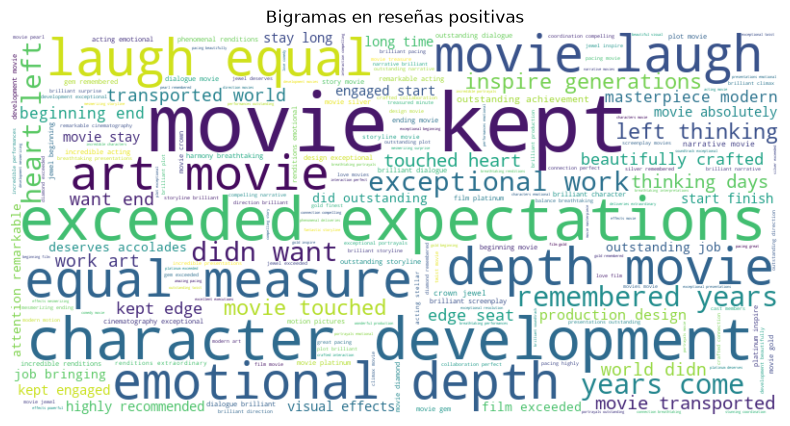

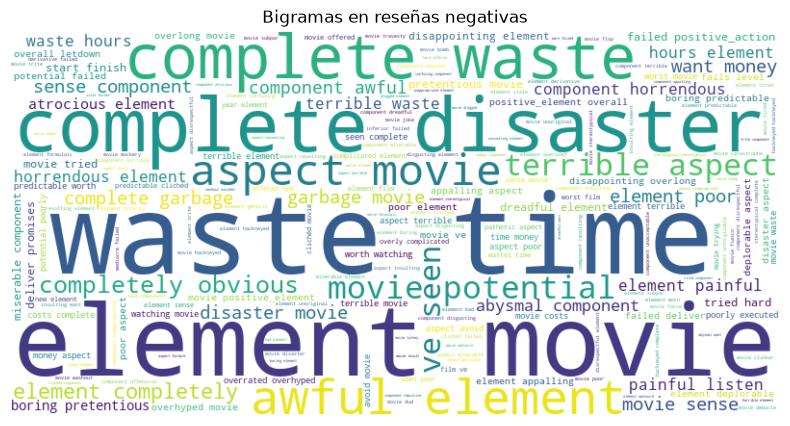

In [20]:
# TODO: Implemente generate_ngram_wordcloud(texts, ngram_size=2, title=None, stop_words=True).
# Pista: CountVectorizer(ngram_range=(n,n)) y WordCloud.generate_from_frequencies.
# Compare n-gramas positivos y negativos.
def generate_ngram_wordcloud(texts, ngram_size=2, title=None, stop_words=True):
    vectorizer = CountVectorizer(ngram_range=(ngram_size, ngram_size),
                                 stop_words="english" if stop_words else None)
    X = vectorizer.fit_transform(texts)
    counts = X.sum(axis=0).A1
    freqs = dict(zip(vectorizer.get_feature_names_out(), counts))

    wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(freqs)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title or f"Nube de {ngram_size}-gramas")
    plt.show()

generate_ngram_wordcloud(pos_texts, title="Bigramas en reseñas positivas")
generate_ngram_wordcloud(neg_texts, title="Bigramas en reseñas negativas")

In [22]:
# TODO: Explore ejemplos de reseñas de una clase.
# Revise antes el formato real de LABEL_COL y sus etiquetas.
# Formato de la etiqueta
print("Tipo:", df[LABEL_COL].dtype)
print("Valores:", df[LABEL_COL].unique())

# Muestra de reseñas negativas
negativas = df[df[LABEL_COL] == 0]
muestra = negativas.sample(5, random_state=RANDOM_STATE)

for i, texto in enumerate(muestra[TEXT_COL], start=1):
    print(f"{i}. {texto}\n")

Tipo: int64
Valores: [1 0]
1. Worst movie I've ever seen. Complete disaster. The {aspect} were unforgivable and the {element} was boring.

2. Atrocious {element} and deplorable {aspect}. This is a farce that fails on every level.

3. Pathetic {aspect} and terrible {element}. This film is a travesty that wastes everyone's time.

4. Overrated and overhyped. The movie was tired and the {component} were terrible.

5. Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.



## 1.4 Polaridad léxica exploratoria

Antes de entrenar modelos, podemos hacer una aproximación simple basada en diccionarios.

La idea es contar palabras positivas y negativas en cada review.  
Esto no reemplaza un modelo de machine learning, pero ayuda a entender el problema.

Limitaciones:

- No entiende contexto.
- No entiende sarcasmo.
- No maneja bien negaciones.
- Depende mucho de la lista de palabras.

En ambas clases: {'movie', 'film'}
Accuracy : 0.925
Precision: 1.0
Recall   : 0.85
F1       : 0.918918918918919


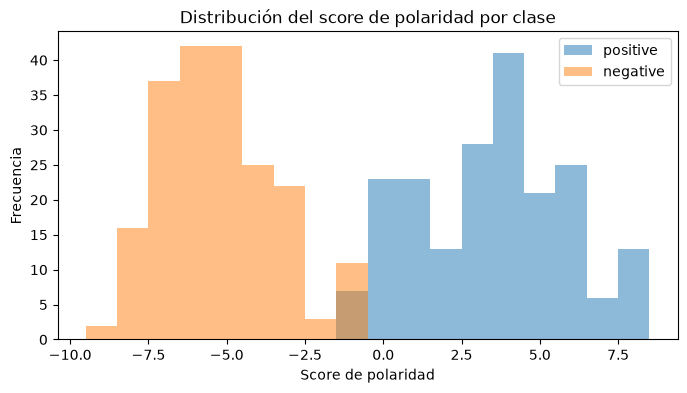

In [23]:
# TODO: Construya un clasificador exploratorio basado en polaridad léxica.
# 1. Obtenga palabras frecuentes por clase y compare vocabularios.
# 2. Defina una función calc_polarity(text).
# 3. Obtenga predicciones, calcule precisión, recall, F1 y accuracy.
# 4. Visualice la distribución de scores por clase.
# Evite usar información del conjunto de prueba para construir vocabularios si evalúa generalización.

# 0. Separación train / test
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=df[LABEL_COL])

# 1. Vocabularios por clase (solo con train)
top_pos = {w for w, _ in get_top_words(train_df[train_df[LABEL_COL] == 1][TEXT_COL], n=50, remove_stopwords=True)}
top_neg = {w for w, _ in get_top_words(train_df[train_df[LABEL_COL] == 0][TEXT_COL], n=50, remove_stopwords=True)}

print("En ambas clases:", top_pos & top_neg)
pos_words = top_pos - top_neg
neg_words = top_neg - top_pos

# 2. Función de polaridad
def calc_polarity(text):
    tokens = simple_tokenize(text)
    pos = sum(token in pos_words for token in tokens)
    neg = sum(token in neg_words for token in tokens)
    return pos-neg  # score de polaridad: positivo - negativo

# 3. Predicciones y métricas (solo con test)
test_scores = test_df[TEXT_COL].apply(calc_polarity)
y_pred = (test_scores > 0).astype(int)
y_true = test_df[LABEL_COL]

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1       :", f1_score(y_true, y_pred))

# 4. Distribución de scores por clase
bins = np.arange(test_scores.min(), test_scores.max() + 2) - 0.5
plt.figure(figsize=(8, 4))
for valor, nombre in [(1, "positive"), (0, "negative")]:
    plt.hist(test_scores[y_true == valor], bins=bins, alpha=0.5, label=nombre)
plt.title("Distribución del score de polaridad por clase")
plt.xlabel("Score de polaridad")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

## Ejercicio 1

1. Identifique las 10 palabras más frecuentes en reviews positivas y negativas.

   **Respuesta:** Sin contar stop words:

   - **Positivas:** movie, outstanding, brilliant, exceptional, incredible, end, film, kept, remarkable, beginning.
   - **Negativas:** element, movie, aspect, complete, component, terrible, waste, time, failed, poor.

   En las positivas mandan los adjetivos de elogio. En las negativas se cuelan `element`, `aspect` y `component`, que no son palabras reales de las reseñas sino plantillas que quedaron sin rellenar (`{element}`).

In [24]:
# Pregunta 1: top 10 de palabras por clase (sin stop words)
top10_pos = get_top_words(pos_texts, n=10, remove_stopwords=True)
top10_neg = get_top_words(neg_texts, n=10, remove_stopwords=True)

pd.DataFrame({
    "positiva": [w for w, _ in top10_pos],
    "freq_pos": [f for _, f in top10_pos],
    "negativa": [w for w, _ in top10_neg],
    "freq_neg": [f for _, f in top10_neg],
}, index=range(1, 11))

,positiva,freq_pos,negativa,freq_neg
1,movie,473,element,823
2,outstanding,258,movie,811
3,brilliant,172,aspect,382
4,exceptional,165,complete,289
5,incredible,131,component,267
6,end,108,terrible,255
7,film,107,waste,213
8,kept,100,time,203
9,remarkable,100,failed,149
10,beginning,97,poor,128


2. ¿Hay palabras que aparecen en ambas clases?

   **Respuesta:** Sí, pero muy pocas. En el top 10 solo se repite `movie`, y en todo el vocabulario apenas coinciden 6 palabras: `film`, `finish`, `movie`, `start`, `time` y `want`. Son palabras neutras que no ayudan a distinguir el sentimiento. Que los vocabularios estén tan separados es raro en reseñas reales y sugiere que el dataset es sintético.

In [25]:
# Pregunta 2: palabras compartidas entre clases
pos_set_10 = {w for w, _ in top10_pos}
neg_set_10 = {w for w, _ in top10_neg}
print("Compartidas en el top 10:", pos_set_10 & neg_set_10)

vocab_pos = {w for w, _ in get_top_words(pos_texts, n=None, remove_stopwords=True)}
vocab_neg = {w for w, _ in get_top_words(neg_texts, n=None, remove_stopwords=True)}
print("Vocabulario positivo:", len(vocab_pos))
print("Vocabulario negativo:", len(vocab_neg))
print("Compartidas en todo el vocabulario:", sorted(vocab_pos & vocab_neg))

Compartidas en el top 10: {'movie'}
Vocabulario positivo: 182
Vocabulario negativo: 133
Compartidas en todo el vocabulario: ['film', 'finish', 'movie', 'start', 'time', 'want']


3. ¿Qué problema puede causar una palabra muy frecuente como `movie` o `film`?

   **Respuesta:** `movie` está en el 64 % de las reseñas, tanto buenas como malas, así que no dice nada del sentimiento. Aun así domina los conteos y le quita protagonismo a palabras que sí informan, como `brilliant` o `terrible`. Además puede engañar al modelo: aquí aparece más en las negativas (811 veces contra 473), y el modelo podría aprender que `movie` "suena negativo". TF-IDF ayuda a bajarle el peso.

In [26]:
# Pregunta 3: peso de "movie" y "film" en el corpus
for palabra in ["movie", "film"]:
    pct_docs = df[TEXT_COL].str.lower().str.contains(rf"\b{palabra}\b").mean() * 100
    print(f"{palabra}: {vocab[palabra]} apariciones, en el {pct_docs:.1f} % de las reseñas")

pct_alguna = df[TEXT_COL].str.lower().str.contains(r"\b(?:movie|film)\b").mean() * 100
print(f"Reseñas con 'movie' o 'film': {pct_alguna:.1f} %")

# Frecuencia de "movie" en cada clase
print("movie en positivas:", dict(top10_pos)["movie"])
print("movie en negativas:", dict(top10_neg)["movie"])

movie: 1284 apariciones, en el 64.2 % de las reseñas
film: 193 apariciones, en el 9.7 % de las reseñas
Reseñas con 'movie' o 'film': 73.4 %
movie en positivas: 473
movie en negativas: 811


4. Encuentre 5 palabras raras y explique si parecen útiles o ruido.

   **Respuesta:** Solo hay 7 palabras que aparecen una única vez. Cinco de ellas:

   - `loved`, `uplifting` y `offended`: por significado son útiles, porque expresan sentimiento claro. El problema es que con una sola aparición el modelo no alcanza a aprender nada confiable de ellas.
   - `filmmaker`: ruido, no expresa ninguna opinión.
   - `let`: sola no dice nada, pero viene de *"the movie let me down"*, que sí es negativa. Serviría como bigrama, no como palabra suelta.

In [27]:
# Pregunta 4: palabras raras, su clase y la reseña donde aparecen
for palabra in hapax:
    fila = df[df[TEXT_COL].str.lower().str.contains(rf"\b{palabra}\b")].iloc[0]
    print(f"{palabra} -> clase {fila[LABEL_COL]}: {fila[TEXT_COL]}")

let -> clase 0: Boring and predictable. Not worth watching. The movie let me down and the {element} was completely obvious.
down -> clase 0: Boring and predictable. Not worth watching. The movie let me down and the {element} was completely obvious.
loved -> clase 1: This movie is absolutely outstanding! I loved every minute of it. The direction was stunning and the surprise was breathtaking.
adored -> clase 1: This movie is absolutely engaging! I adored every minute of it. The direction was outstanding and the story was significant.
filmmaker -> clase 1: This film exceeded all my expectations. The filmmaker did an outstanding job bringing this character development to life.
offended -> clase 0: Boring and predictable. Not worth watching. The movie offended me and the {element} was completely obvious.
uplifting -> clase 1: Amazing pacing and great ending. Highly recommended! The interaction was beautiful and the roles were uplifting.


# 2. Text Normalizing and Cleaning

La normalización textual busca transformar el texto a una forma más consistente.

Ejemplos de operaciones comunes:

- Pasar a minúsculas.
- Eliminar HTML.
- Eliminar URLs.
- Eliminar puntuación.
- Eliminar caracteres no alfabéticos.
- Tokenizar.
- Remover stop words.
- Manejar negaciones.
- Reducir ruido.

Importante: limpiar más no siempre significa mejorar.  
En análisis de sentimiento, algunas palabras aparentemente simples como `not`, `no` o `never` pueden cambiar completamente el significado.

Por ejemplo:

> `not good` no debería convertirse simplemente en `good`.

Por eso en este notebook vamos a conservar algunas negaciones importantes.

In [28]:
# TODO: Construya CUSTOM_STOP_WORDS conservando negaciones relevantes para sentimiento.
# TODO: Implemente clean_text(text): minúsculas, HTML, URLs, caracteres, stop words.
# TODO: Cree df["review_clean"] y compare con el original.
# Pista: re.sub y ENGLISH_STOP_WORDS.
import unicodedata

NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither", "nowhere", "cannot", "without"}
#SENTIMENT_WORDS = {"but", "too", "very", "must", "more", "most", "less", "only", "against", "enough"}

CUSTOM_STOP_WORDS = ENGLISH_STOP_WORDS - NEGATIONS

def strip_accents(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")


def clean_text(text):
    text = text.lower()
    text = strip_accents(text)                     # quita acentos y diacríticos
    text = re.sub(r"n't\b", " not", text)          # contracciones negativas
    text = re.sub(r"<.*?>", " ", text)             # HTML
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"\{\w+\}", " ", text)           # plantillas sin rellenar del dataset
    text = re.sub(r"[^a-z\s]", " ", text)          # solo letras
    tokens = [token for token in text.split() if token not in CUSTOM_STOP_WORDS]
    return " ".join(tokens)

df["review_clean"] = df[TEXT_COL].apply(clean_text)
df[[TEXT_COL, "review_clean"]].head(10)

,review,review_clean
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,stunning coordination compelling dialogue movie kept engaged start finish
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,boring predictable not worth watching movie disappointed completely obvious
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,incredible production design engaging narrative movie kept edge seat
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,exceptional work art movie touched heart left thinking days
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,atrocious deplorable turkey fails level
5,Terrible waste of two hours. The {element} was inferior and the {element} was painful to listen to.,terrible waste hours inferior painful listen
6,Outstanding character development and brilliant screenplay. This is how movies should be made.,outstanding character development brilliant screenplay movies
7,Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.,disappointing overlong movie overall letdown
8,Brilliant screenplay with exceptional acting. This is platinum at its finest.,brilliant screenplay exceptional acting platinum finest
9,Fantastic storyline and wonderful dialogue. The movie was a platinum that exceeded all expectations.,fantastic storyline wonderful dialogue movie platinum exceeded expectations


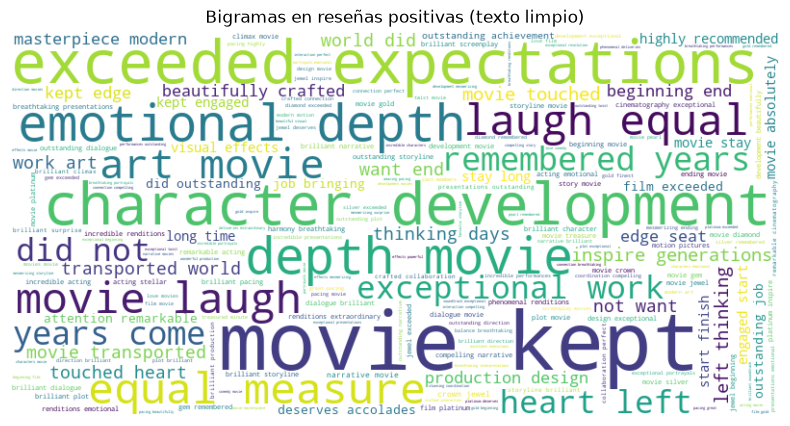

In [29]:
# TODO: Genere una nube de n-gramas de reseñas positivas limpias.
pos_clean = df[df[LABEL_COL] == 1]["review_clean"]

generate_ngram_wordcloud(pos_clean, ngram_size=2, title="Bigramas en reseñas positivas (texto limpio)", stop_words=False)


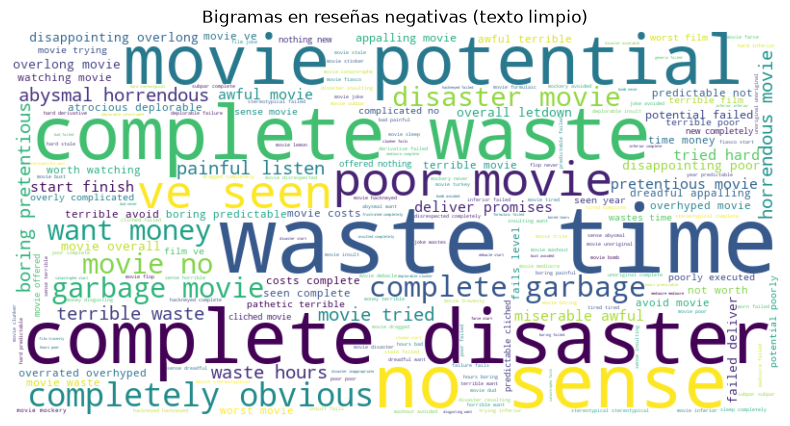

In [30]:
# TODO: Genere una nube de n-gramas de reseñas negativas limpias.
neg_clean = df[df[LABEL_COL] == 0]["review_clean"]

generate_ngram_wordcloud(neg_clean, ngram_size=2, title="Bigramas en reseñas negativas (texto limpio)", stop_words=False)

,num_words,num_words_clean
count,2000.000000,2000.000000
mean,15.222500,7.516500
std,1.895466,1.460751
min,11.000000,5.000000
25%,14.000000,7.000000
50%,15.000000,8.000000
75%,17.000000,9.000000
max,22.000000,11.000000


,num_words,num_words_clean
sentiment,,
0,15.057,6.801
1,15.388,8.232


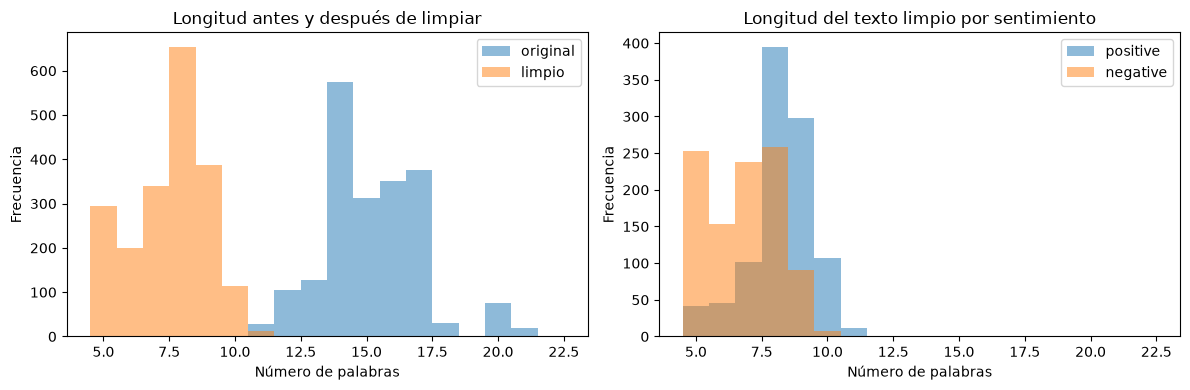

In [31]:
# TODO: Compare longitudes antes y después de limpiar.
# Calcule num_words_clean y visualice histogramas.
# 1. Longitud después de limpiar
df["num_words_clean"] = df["review_clean"].apply(lambda x: len(x.split()))

# 2. Comparación numérica
display(df[["num_words", "num_words_clean"]].describe())
display(df.groupby(LABEL_COL)[["num_words", "num_words_clean"]].mean())

# 3. Histogramas
bins = np.arange(df["num_words_clean"].min(), df["num_words"].max() + 2) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Antes vs después
axes[0].hist(df["num_words"], bins=bins, alpha=0.5, label="original")
axes[0].hist(df["num_words_clean"], bins=bins, alpha=0.5, label="limpio")
axes[0].set_title("Longitud antes y después de limpiar")
axes[0].set_xlabel("Número de palabras")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

# Texto limpio por sentimiento
for valor, nombre in [(1, "positive"), (0, "negative")]:
    subset = df[df[LABEL_COL] == valor]
    axes[1].hist(subset["num_words_clean"], bins=bins, alpha=0.5, label=nombre)
axes[1].set_title("Longitud del texto limpio por sentimiento")
axes[1].set_xlabel("Número de palabras")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

plt.tight_layout()
plt.show()

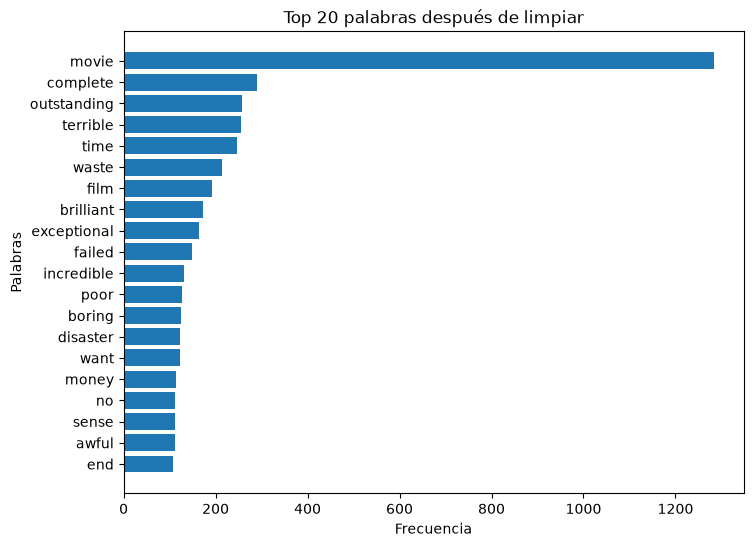

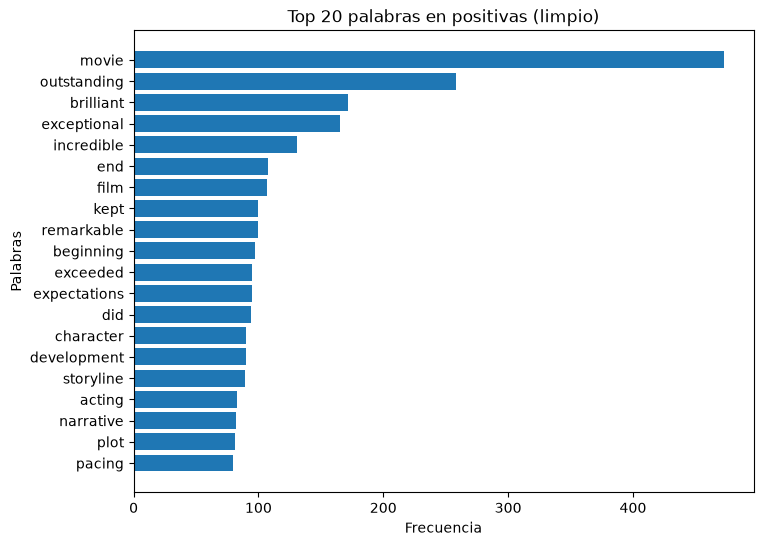

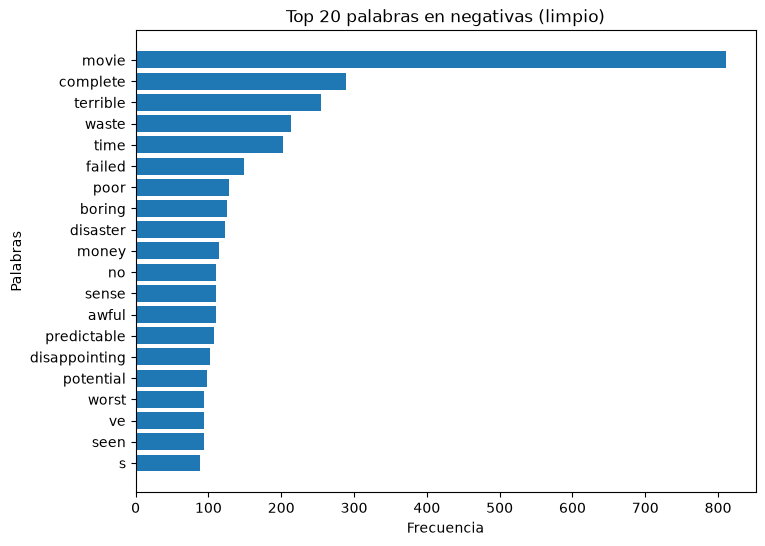

In [32]:
# TODO: Grafique las palabras más frecuentes después de limpiar.

# Textos limpios
clean_all = df["review_clean"]
clean_pos = df[df[LABEL_COL] == 1]["review_clean"]
clean_neg = df[df[LABEL_COL] == 0]["review_clean"]

# Palabras más frecuentes (sin volver a quitar stop words)
plot_top_words(get_top_words(clean_all, n=20), "Top 20 palabras después de limpiar")
plot_top_words(get_top_words(clean_pos, n=20), "Top 20 palabras en positivas (limpio)")
plot_top_words(get_top_words(clean_neg, n=20), "Top 20 palabras en negativas (limpio)")

En ambas clases: {'movie', 'film'}


,original,limpio
accuracy,0.925000,0.925000
precision,1.000000,1.000000
recall,0.850000,0.850000
f1,0.918919,0.918919


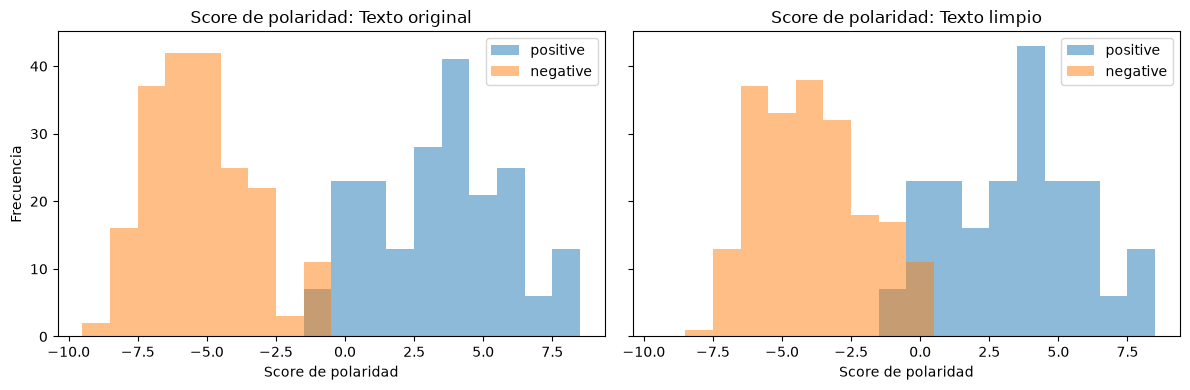

In [33]:
# TODO: Repita el análisis exploratorio de polaridad con texto limpio.
# Compare métricas y distribución de los scores.
# 0. Misma separación, texto limpio
train_clean = df.loc[train_df.index, "review_clean"]
test_clean = df.loc[test_df.index, "review_clean"]
y_train_pol = train_df[LABEL_COL]

# 1. Vocabularios por clase (solo train, sin volver a quitar stop words)
top_pos_clean = {w for w, _ in get_top_words(train_clean[y_train_pol == 1], n=50)}
top_neg_clean = {w for w, _ in get_top_words(train_clean[y_train_pol == 0], n=50)}

print("En ambas clases:", top_pos_clean & top_neg_clean)
pos_words_clean = top_pos_clean - top_neg_clean
neg_words_clean = top_neg_clean - top_pos_clean

# 2. Función de polaridad para texto limpio
def calc_polarity_clean(text):
    tokens = text.split()
    pos = sum(token in pos_words_clean for token in tokens)
    neg = sum(token in neg_words_clean for token in tokens)
    return pos - neg

# 3. Predicciones y comparación de métricas
test_scores_clean = test_clean.apply(calc_polarity_clean)
y_pred_clean = (test_scores_clean > 0).astype(int)

comparacion = pd.DataFrame({
    "original": [accuracy_score(y_true, y_pred), precision_score(y_true, y_pred),
                 recall_score(y_true, y_pred), f1_score(y_true, y_pred)],
    "limpio":   [accuracy_score(y_true, y_pred_clean), precision_score(y_true, y_pred_clean),
                 recall_score(y_true, y_pred_clean), f1_score(y_true, y_pred_clean)],
}, index=["accuracy", "precision", "recall", "f1"])
display(comparacion)

# 4. Distribución de scores: original vs limpio
bins = np.arange(min(test_scores.min(), test_scores_clean.min()),
                 max(test_scores.max(), test_scores_clean.max()) + 2) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, scores, titulo in [(axes[0], test_scores, "Texto original"),
                           (axes[1], test_scores_clean, "Texto limpio")]:
    for valor, nombre in [(1, "positive"), (0, "negative")]:
        ax.hist(scores[y_true == valor], bins=bins, alpha=0.5, label=nombre)
    ax.set_title(f"Score de polaridad: {titulo}")
    ax.set_xlabel("Score de polaridad")
    ax.legend()
axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 2.1 División entrenamiento / prueba

Usaremos la misma división de datos para todos los experimentos.  
Esto hace que la comparación entre métodos sea justa.

- Train: datos usados para entrenar.
- Test: datos usados para evaluar.
- Stratify: mantiene proporciones similares de clases en train y test.

In [34]:
# TODO:
# Cree X_raw, X_clean, y.
# Divida en train y test usando train_test_split.
# Use test_size=0.2, random_state=42 y stratify=y.

X_raw = df[TEXT_COL]
X_clean = df["review_clean"]
y = df[LABEL_COL]

(
    X_raw_train, 
    X_raw_test, 
    X_clean_train, 
    X_clean_test, 
    y_train, 
    y_test 
)= train_test_split(
    X_raw, X_clean, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train:", len(X_raw_train), "| Test:", len(X_raw_test))
print("Clases en train:", y_train.value_counts().to_dict())
print("Clases en test:", y_test.value_counts().to_dict())

Train: 1600 | Test: 400
Clases en train: {1: 800, 0: 800}
Clases en test: {0: 200, 1: 200}


## Ejercicio 2

1. Tome 5 reviews y compare manualmente el texto original contra el texto limpio.

   **Respuesta:**

   | # | Original | Limpio | Qué cambió |
   |---|---|---|---|
   | 54 | …I didn't want it to end. | …did not want end | `didn't` pasó a `did not`; la negación se conserva. |
   | 1 | …Not worth watching… the {element} was completely obvious. | …not worth watching… completely obvious | Se conserva `not` y desaparece la plantilla. |
   | 7 | …had some {positive_element} but overall it was a letdown. | …movie overall letdown | Se pierde el `but` que marcaba el contraste. |
   | 17 | …Must watch! The balance… | …watch balance… | Se pierden `must` y el signo `!`. |
   | 92 | …made no sense… too clichéd and failed. | …no sense… cliched failed | Se conserva `no`, `clichéd` queda sin tilde y se pierde `too`. |

   En general la limpieza deja los adjetivos y las negaciones, y reduce cada reseña más o menos a la mitad.

In [35]:
# Pregunta 1: comparación de 5 reseñas originales y limpias
ejemplos = [54, 1, 7, 17, 92]
for idx in ejemplos:
    print(f"[{idx}] clase {df.loc[idx, LABEL_COL]}")
    print("  Original:", df.loc[idx, TEXT_COL])
    print("  Limpio:  ", df.loc[idx, "review_clean"])
    print()

[54] clase 1
  Original: This is why I love cinema. The movie transported me to another world and I didn't want it to end.
  Limpio:   love cinema movie transported world did not want end

[1] clase 0
  Original: Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.
  Limpio:   boring predictable not worth watching movie disappointed completely obvious

[7] clase 0
  Original: Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.
  Limpio:   disappointing overlong movie overall letdown

[17] clase 1
  Original: Excellent performances by all talents. Must watch! The balance between the talents was exceptional.
  Limpio:   excellent performances talents watch balance talents exceptional

[92] clase 0
  Original: Overly complicated {element} that made no sense. The movie was trying to be too clichéd and failed.
  Limpio:   overly complicated no sense movie trying cliched failed



2. ¿Qué información útil se perdió durante la limpieza?

   **Respuesta:** Sobre todo palabras que la lista de stop words elimina pero que sí aportan al sentimiento: `but` (149 veces), que marca un giro en la opinión; `too` (98), que intensifica; y `must` (43), que en *"Must watch!"* es una recomendación. También se pierden los signos de exclamación, que aparecían solo en reseñas positivas (132), y quedan restos sin sentido de algunas contracciones, como `ve` (de *I've*) y `s` (de *it's*).

In [36]:
# Pregunta 2: información perdida
# Stop words con significado que la limpieza eliminó
removed = Counter()
for text in df[TEXT_COL]:
    removed.update(w for w in re.findall(r"[a-z]+", text.lower()) if w in CUSTOM_STOP_WORDS)
print("Stop words útiles eliminadas:", {w: removed[w] for w in ["but", "too", "must", "all", "every"]})

# Signos de exclamación por clase (desaparecen al limpiar)
print("Signos '!' por clase:", df[TEXT_COL].str.count("!").groupby(df[LABEL_COL]).sum().to_dict())

# Tokens sueltos generados por la limpieza
clean_vocab = Counter(w for text in df["review_clean"] for w in text.split())
print("Tokens residuales:", {w: clean_vocab[w] for w in ["ve", "s"]})

# Acentos: la palabra se conserva sin tilde en lugar de partirse
print("clichéd ->", clean_text("too clichéd"), "| cliched:", clean_vocab["cliched"], "| clich:", clean_vocab["clich"], "| d:", clean_vocab["d"])

Stop words útiles eliminadas: {'but': 149, 'too': 98, 'must': 43, 'all': 223, 'every': 143}
Signos '!' por clase: {0: 0, 1: 132}
Tokens residuales: {'ve': 94, 's': 89}
clichéd -> cliched | cliched: 60 | clich: 0 | d: 0


3. ¿Qué ruido se eliminó?

   **Respuesta:** Lo más importante fueron las plantillas sin rellenar (`{element}`, `{aspect}`, `{component}`…): estaban en 937 reseñas negativas y en ninguna positiva, así que prácticamente delataban la etiqueta. También se quitaron las stop words, la puntuación, las mayúsculas y las tildes, con lo que las reseñas pasaron de 15,2 a 7,5 palabras en promedio. La función también elimina HTML y URLs, aunque este dataset no tenía.

In [37]:
# Pregunta 3: ruido eliminado
con_plantilla = df[TEXT_COL].str.contains(r"\{\w+\}")
print("Reseñas con plantillas {...} antes:", con_plantilla.sum())
print("Reseñas con plantillas después:  ", df["review_clean"].str.contains(r"\b(?:element|aspect|component)\b").sum())
print("Plantillas por clase:", con_plantilla.groupby(df[LABEL_COL]).sum().to_dict())
print(f"Palabras promedio: {df['num_words'].mean():.1f} -> {df['num_words_clean'].mean():.1f}")
print("Reseñas con HTML:", df[TEXT_COL].str.contains("<").sum(), "| con URLs:", df[TEXT_COL].str.contains("http|www").sum())

Reseñas con plantillas {...} antes: 937
Reseñas con plantillas después:   0
Plantillas por clase: {0: 937, 1: 0}
Palabras promedio: 15.2 -> 7.5
Reseñas con HTML: 0 | con URLs: 0


4. ¿Por qué es importante conservar palabras como `not`, `no` y `never`?

   **Respuesta:** Porque cambian por completo el sentido de la frase. Sin ellas, *"Not worth watching"* queda como `worth watching` y *"made no sense"* como `made sense`, es decir, lo contrario de lo que se dijo. En este dataset 271 reseñas tienen alguna negación y la limpieza las conserva todas. Eso sí, el modelo las ve como palabras sueltas; para captar bien expresiones como `not worth` harían falta bigramas.

In [38]:
# Pregunta 4: negaciones antes y después de limpiar
print("Reseñas con negación (original):", df[TEXT_COL].str.contains(r"\b(?:not|no|never)\b|n't", case=False).groupby(df[LABEL_COL]).sum().to_dict())
print("Reseñas con negación (limpio):  ", df["review_clean"].str.contains(r"\b(?:not|no|never)\b").groupby(df[LABEL_COL]).sum().to_dict())

# Qué pasaría si se usara la lista estándar, que elimina las negaciones
def clean_sin_negaciones(text):
    return " ".join(t for t in clean_text(text).split() if t not in ENGLISH_STOP_WORDS)

for idx in [1, 92]:
    print(f"\n[{idx}] {df.loc[idx, TEXT_COL]}")
    print("  Con negaciones:", df.loc[idx, "review_clean"])
    print("  Sin negaciones:", clean_sin_negaciones(df.loc[idx, TEXT_COL]))

Reseñas con negación (original): {0: 215, 1: 56}
Reseñas con negación (limpio):   {0: 215, 1: 56}

[1] Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.
  Con negaciones: boring predictable not worth watching movie disappointed completely obvious
  Sin negaciones: boring predictable worth watching movie disappointed completely obvious

[92] Overly complicated {element} that made no sense. The movie was trying to be too clichéd and failed.
  Con negaciones: overly complicated no sense movie trying cliched failed
  Sin negaciones: overly complicated sense movie trying cliched failed


# Funciones auxiliares para entrenamiento y evaluación

Antes de entrenar los modelos, vamos a definir una función reutilizable.  
Esto evita repetir código en cada representación.

Todos los experimentos usarán:

- La misma división train/test.
- El mismo modelo: Logistic Regression.
- Las mismas métricas.

In [57]:
# TODO:
# Implemente una función train_and_evaluate que reciba:
# - vectorizer
# - X_train_text
# - X_test_text
# - y_train
# - y_test
# - experiment_name
#
# La función debe:
# 1. Ajustar el vectorizer con train.
# 2. Transformar train y test.
# 3. Entrenar LogisticRegression.
# 4. Predecir.
# 5. Calcular Accuracy, Precision, Recall, F1 y ROC-AUC.
# 6. Retornar un diccionario con resultados y objetos útiles.

def train_and_evaluate(vectorizer, X_train_text, X_test_text, y_train, y_test, experiment_name):
    # 1. Ajustar el vectorizer con train
    X_train = vectorizer.fit_transform(X_train_text)
    X_test = vectorizer.transform(X_test_text)

    # 2. Entrenar LogisticRegression
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    # 3. Predecir
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]  # Probabilidad de la clase positiva

    # 4. Calcular métricas
    return {
        "experiment": experiment_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred,zero_division=0),
        "recall": recall_score(y_test, y_pred,zero_division=0),
        "f1": f1_score(y_test, y_pred,zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "vocabulary_size": len(vectorizer.get_feature_names_out()),
        "n_features": X_train.shape[1],
        "model": model,
        "vectorizer": vectorizer,
        "y_pred": y_pred,
        "y_proba": y_proba,
        "x_train": X_train,
        "x_test": X_test,
        "y_true": np.asarray(y_test)
    }


# Lista global donde se acumulan los resultados de todos los experimentos
all_results = []


# 3. Sentiment Analysis con One-Hot / Binary Encoding

En texto, una forma simple de representar documentos es indicar si una palabra aparece o no aparece.

Ejemplo:

| review | amazing | boring | movie |
|---|---:|---:|---:|
| `amazing movie` | 1 | 0 | 1 |
| `boring movie` | 0 | 1 | 1 |

En este notebook usaremos `CountVectorizer(binary=True)`.  
Técnicamente, para documentos completos esto se conoce mejor como **binary bag-of-words** o **multi-hot encoding**, porque cada documento puede activar muchas palabras.

La idea es enseñar el principio de presencia/ausencia de palabras.

In [58]:
# TODO:
# Entrene dos modelos:
# 1. Binary Encoding con texto original.
# 2. Binary Encoding con texto limpio.
#
# Use CountVectorizer(binary=True, max_features=5000)

# binary_raw_result = ...
# binary_clean_result = ...

# all_results.extend([...])

binary_raw_result = train_and_evaluate(
    CountVectorizer(binary=True, max_features=5000),
    X_raw_train, X_raw_test, y_train, y_test,
    "Binary - original",
)
binary_clean_result = train_and_evaluate(
    CountVectorizer(binary=True, max_features=5000),
    X_clean_train, X_clean_test, y_train, y_test,
    "Binary - limpio",
)

all_results.extend([binary_raw_result, binary_clean_result])

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
pd.DataFrame([binary_raw_result, binary_clean_result]).set_index("experiment")[metricas].T

experiment,Binary - original,Binary - limpio
accuracy,1.0,1.0
precision,1.0,1.0
recall,1.0,1.0
f1,1.0,1.0
roc_auc,1.0,1.0
n_features,358.0,303.0


## Ejercicio 3

1. Explique con sus palabras qué significa que una matriz textual sea dispersa.

   **Respuesta:** Que casi todas sus celdas son ceros. Cada fila es una reseña y cada columna una palabra del vocabulario, pero una reseña solo usa unas pocas palabras. Aquí la matriz tiene 358 columnas y cada reseña activa unas 14, así que el 96 % de las celdas está en cero (97,6 % con texto limpio). Por eso se guarda en un formato especial que solo almacena los valores distintos de cero.

In [48]:
# Pregunta 1: dispersión de las matrices binarias de entrenamiento
for r in [binary_raw_result, binary_clean_result]:
    X = r["x_train"]
    total = X.shape[0] * X.shape[1]
    print(r["experiment"])
    print(f"  Forma: {X.shape[0]} reseñas x {X.shape[1]} palabras = {total:,} celdas")
    print(f"  Celdas distintas de cero: {X.nnz:,}")
    print(f"  Dispersión: {1 - X.nnz / total:.1%}")
    print(f"  Palabras activas por reseña: {X.nnz / X.shape[0]:.1f}")

Binary - original
  Forma: 1600 reseñas x 358 palabras = 572,800 celdas
  Celdas distintas de cero: 22,260
  Dispersión: 96.1%
  Palabras activas por reseña: 13.9
Binary - limpio
  Forma: 1600 reseñas x 303 palabras = 484,800 celdas
  Celdas distintas de cero: 11,815
  Dispersión: 97.6%
  Palabras activas por reseña: 7.4


2. ¿Qué diferencia hay entre contar si una palabra aparece y contar cuántas veces aparece?

   **Respuesta:** Binary solo marca si la palabra está (1) o no (0); BoW guarda cuántas veces aparece. En la reseña 17, `talents` sale dos veces: en Binary vale 1 y en BoW vale 2. En este dataset la diferencia casi no se nota, porque las reseñas son cortas y, con texto limpio, solo 106 de 1.600 repiten alguna palabra.

In [54]:
# Pregunta 2: presencia (Binary) frente a frecuencia (conteo) en la reseña 17
texto = df.loc[17, TEXT_COL]
print(texto, "\n")

vec_bin = CountVectorizer(binary=True).fit([texto])
vec_cnt = CountVectorizer(binary=False).fit([texto])
comparacion = pd.DataFrame({
    "binary": vec_bin.transform([texto]).toarray()[0],
    "conteo": vec_cnt.transform([texto]).toarray()[0],
}, index=vec_bin.get_feature_names_out())
display(comparacion.T)

# Cuántas reseñas de entrenamiento repiten alguna palabra
for nombre, X_text in [("original", X_raw_train), ("limpio", X_clean_train)]:
    X_cnt = CountVectorizer().fit_transform(X_text)
    repetidas = (X_cnt.max(axis=1).toarray().ravel() > 1).sum()
    print(f"Reseñas con alguna palabra repetida ({nombre}): {repetidas} de {X_cnt.shape[0]}")

Excellent performances by all talents. Must watch! The balance between the talents was exceptional. 



,all,balance,between,by,excellent,exceptional,must,performances,talents,the,was,watch
binary,1,1,1,1,1,1,1,1,1,1,1,1
conteo,1,1,1,1,1,1,1,1,2,2,1,1


Reseñas con alguna palabra repetida (original): 814 de 1600
Reseñas con alguna palabra repetida (limpio): 106 de 1600


3. Compare los resultados del Binary Encoding con texto original y texto limpio.

   **Respuesta:** Los dos modelos aciertan todo: accuracy, F1 y ROC-AUC dan 1,0 en ambos. Las diferencias son menores: el texto limpio usa menos palabras (303 contra 358) y el original queda un poco más seguro de sus predicciones (log loss de 0,0085 contra 0,0147), porque conserva las plantillas, que son una pista casi infalible de las negativas.

In [50]:
# Pregunta 3: comparación de Binary con texto original y limpio
from sklearn.metrics import log_loss

filas = []
for r in [binary_raw_result, binary_clean_result]:
    confianza = np.maximum(r["y_proba"], 1 - r["y_proba"])
    filas.append({
        "experimento": r["experiment"],
        "accuracy": r["accuracy"],
        "f1": r["f1"],
        "roc_auc": r["roc_auc"],
        "features": r["n_features"],
        "dispersion": 1 - r["x_train"].nnz / (r["x_train"].shape[0] * r["x_train"].shape[1]),
        "log_loss": log_loss(y_test, r["y_proba"]),
        "confianza_media": confianza.mean(),
        "confianza_minima": confianza.min(),
    })
pd.DataFrame(filas).set_index("experimento").T.round(4)

experimento,Binary - original,Binary - limpio
accuracy,1.0000,1.0000
f1,1.0000,1.0000
roc_auc,1.0000,1.0000
features,358.0000,303.0000
dispersion,0.9611,0.9756
log_loss,0.0085,0.0147
confianza_media,0.9916,0.9854
confianza_minima,0.9691,0.9288


4. ¿La limpieza mejoró el resultado? Explique una posible razón.

   **Respuesta:** No lo mejoró, pero porque no había nada que mejorar: los dos modelos ya acertaban el 100 %. El problema es muy fácil, ya que las palabras de cada clase casi no se mezclan. Lo que sí logra la limpieza es el mismo resultado con 15 % menos de vocabulario.

   Al entrenar con solo 40 reseñas, el texto original rinde más (0,998 contra 0,900 de accuracy), pero es gracias a las plantillas: le basta ver `element` para saber que la reseña es negativa. Esa pista no existiría en reseñas reales, así que el modelo con texto limpio es el más confiable aunque aquí puntúe menos.

In [51]:
# Pregunta 4: efecto de la limpieza con pocos datos de entrenamiento (20 reseñas por clase)
idx_pocos = y_train.groupby(y_train).sample(20, random_state=RANDOM_STATE).index

filas = []
for nombre, X_tr, X_te in [("original", X_raw_train, X_raw_test), ("limpio", X_clean_train, X_clean_test)]:
    r = train_and_evaluate(
        CountVectorizer(binary=True, max_features=5000),
        X_tr.loc[idx_pocos], X_te, y_train.loc[idx_pocos], y_test,
        f"Binary - {nombre} (40 reseñas)",
    )
    tn, fp, fn, tp = confusion_matrix(y_test, r["y_pred"]).ravel()
    filas.append({"experimento": r["experiment"], "accuracy": r["accuracy"], "f1": r["f1"],
                  "positivas_mal_clasificadas": fn, "negativas_mal_clasificadas": fp})
pd.DataFrame(filas).set_index("experimento").round(3)

,accuracy,f1,positivas_mal_clasificadas,negativas_mal_clasificadas
experimento,,,,
Binary - original (40 reseñas),0.998,0.997,1,0
Binary - limpio (40 reseñas),0.900,0.889,40,0


# 4. Sentiment Analysis con Bag of Words

Bag of Words representa cada documento contando cuántas veces aparece cada palabra.

A diferencia del binary encoding, BoW sí conserva frecuencia.

Ejemplo:

| review | amazing | boring | movie |
|---|---:|---:|---:|
| `amazing amazing movie` | 2 | 0 | 1 |
| `boring movie` | 0 | 1 | 1 |

Limitación principal:  
BoW ignora el orden de las palabras.  
Por ejemplo, no distingue bien entre:

- `good`
- `not good`

si no se maneja adecuadamente el contexto.

In [59]:
# TODO:
# Entrene dos modelos:
# 1. BoW con texto original.
# 2. BoW con texto limpio.
#
# Use CountVectorizer(binary=False, max_features=5000)

bow_raw_result = train_and_evaluate(
    CountVectorizer(binary=False, max_features=5000),
    X_raw_train, X_raw_test, y_train, y_test,
    "BoW - original",
)

bow_clean_result = train_and_evaluate(
    CountVectorizer(binary=False, max_features=5000),
    X_clean_train, X_clean_test, y_train, y_test,
    "BoW - limpio",
)

all_results.extend([bow_raw_result, bow_clean_result])

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
pd.DataFrame([bow_raw_result, bow_clean_result]).set_index("experiment")[metricas].T

experiment,BoW - original,BoW - limpio
accuracy,1.0,1.0
precision,1.0,1.0
recall,1.0,1.0
f1,1.0,1.0
roc_auc,1.0,1.0
n_features,358.0,303.0


In [61]:
# TODO:
# Cree una tabla parcial comparando Binary Encoding vs BoW.

from sklearn.metrics import log_loss

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
partial_df = pd.DataFrame(all_results).set_index("experiment")[metricas]
partial_df["log_loss"] = [log_loss(y_test, r["y_proba"]) for r in all_results]
partial_df.sort_values("log_loss").round(4)


,accuracy,precision,recall,f1,roc_auc,n_features,log_loss
experiment,,,,,,,
BoW - original,1.0,1.0,1.0,1.0,1.0,358,0.0077
Binary - original,1.0,1.0,1.0,1.0,1.0,358,0.0085
BoW - limpio,1.0,1.0,1.0,1.0,1.0,303,0.0144
Binary - limpio,1.0,1.0,1.0,1.0,1.0,303,0.0147


## Ejercicio 4

1. ¿Por qué BoW puede funcionar mejor que Binary Encoding?

   **Respuesta:** Porque guarda más información: no solo si la palabra aparece, sino cuántas veces, y la repetición puede indicar énfasis. En este dataset esa ventaja es mínima, porque las reseñas son cortas y casi no repiten palabras. BoW apenas mejora el log loss (0,0077 contra 0,0085) y, al entrenar con pocos datos, ni siquiera supera a Binary.

In [ ]:
# Pregunta 1: Binary frente a BoW con datos completos y con pocos datos
idx_pocos = y_train.groupby(y_train).sample(20, random_state=RANDOM_STATE).index

filas = []
for nombre_vec, binario in [("Binary", True), ("BoW", False)]:
    for nombre_txt, X_tr, X_te in [("original", X_raw_train, X_raw_test), ("limpio", X_clean_train, X_clean_test)]:
        completo = next(r for r in all_results if r["experiment"] == f"{nombre_vec} - {nombre_txt}")
        pocos = train_and_evaluate(CountVectorizer(binary=binario, max_features=5000),
                                   X_tr.loc[idx_pocos], X_te, y_train.loc[idx_pocos], y_test, "pocos datos")
        filas.append({
            "experimento": f"{nombre_vec} - {nombre_txt}",
            "f1_completo": completo["f1"],
            "log_loss_completo": log_loss(y_test, completo["y_proba"]),
            "accuracy_40_reseñas": pocos["accuracy"],
            "f1_40_reseñas": pocos["f1"],
        })
pd.DataFrame(filas).set_index("experimento").round(4)

2. ¿En qué casos la frecuencia de una palabra puede ser útil?

   **Respuesta:** Cuando repetir una palabra expresa intensidad, como en la reseña que dice dos veces `compelling`. También en textos largos, donde ayuda a distinguir una mención de pasada de la idea principal, y en reseñas mixtas: si `great` aparece cinco veces y `boring` una, la opinión general seguramente es positiva.

In [ ]:
# Pregunta 2: reseñas limpias de entrenamiento que repiten palabras de sentimiento
ejemplos_repetidos = [t for t in X_clean_train if Counter(t.split()).most_common(1)[0][1] > 1]
print(f"Reseñas limpias con alguna palabra repetida: {len(ejemplos_repetidos)} de {len(X_clean_train)}\n")
for t in ejemplos_repetidos[:6]:
    repetidas = {w: n for w, n in Counter(t.split()).items() if n > 1}
    print(f"{repetidas} -> {t}")

3. ¿En qué casos la frecuencia puede ser engañosa?

   **Respuesta:** Cuando lo que se repite no tiene que ver con el sentimiento. En el texto original las palabras más repetidas dentro de una reseña son `the`, `and` y `was`. También engaña cuando la repetición es un defecto de los datos: hay reseñas como *"The movie was poor, poor, and a complete waste of time"*, y otras donde `{element}` aparece dos veces, lo que hace que BoW le dé todavía más peso a la plantilla (coeficiente de −2,89 contra −2,78 en Binary). Otros casos típicos son las reseñas muy largas, que acumulan conteos altos solo por su extensión, y el sarcasmo (*"great, just great"*).

In [ ]:
# Pregunta 3: casos donde la frecuencia engaña
# Palabras que más se repiten dentro de una misma reseña (texto original)
repetidas_original = Counter()
for t in X_raw_train:
    repetidas_original.update(w for w, n in Counter(simple_tokenize(t)).items() if n > 1)
print("Más repetidas en el texto original:", repetidas_original.most_common(8))

# La plantilla {element} repetida en una misma reseña
print(f"\nReseña 5: {df.loc[5, TEXT_COL]}")
print("Veces que aparece {element}:", df.loc[5, TEXT_COL].count("{element}"))

# BoW le da más peso a la plantilla que Binary
for r in [binary_raw_result, bow_raw_result]:
    nombres = list(r["vectorizer"].get_feature_names_out())
    print(f"{r['experiment']}: coeficiente de 'element' = {r['model'].coef_[0][nombres.index('element')]:.3f}")

4. Compare BoW con Binary Encoding usando F1-score.

   **Respuesta:** Empatan: los cuatro experimentos tienen F1 de 1,0, así que esta métrica no permite elegir entre los dos. Al entrenar con solo 40 reseñas sí aparecen diferencias: con texto limpio siguen empatados (0,889) y con texto original Binary queda un poco arriba (0,997 contra 0,980). En reseñas tan cortas, contar frecuencias no aporta ventaja sobre marcar presencia.

In [ ]:
# Pregunta 4: F1 de Binary y BoW con datos completos
f1_df = pd.DataFrame(all_results).set_index("experiment")[["f1", "accuracy", "roc_auc"]]
f1_df["log_loss"] = [log_loss(y_test, r["y_proba"]) for r in all_results]
display(f1_df.round(4))

f1_df["f1"].plot(kind="barh", figsize=(7, 3), xlim=(0.9, 1.01), title="F1-score: Binary vs BoW")
plt.xlabel("F1-score")
plt.tight_layout()
plt.show()

# 5. Sentiment Analysis con TF-IDF

TF-IDF significa **Term Frequency - Inverse Document Frequency**.

La intuición es:

- Una palabra es importante si aparece varias veces en un documento.
- Pero pierde importancia si aparece en demasiados documentos.

Por eso TF-IDF ayuda a reducir el peso de palabras demasiado comunes.

Ejemplo:  
`movie` puede aparecer en muchas reseñas, pero no necesariamente indica sentimiento.  
`excellent`, `awful`, `boring` o `wonderful` pueden ser más informativas.

In [ ]:
# TODO:
# Entrene dos modelos:
# 1. TF-IDF con texto original.
# 2. TF-IDF con texto limpio.
#
# Use TfidfVectorizer(max_features=5000)

tfidf_raw_result = train_and_evaluate(
    TfidfVectorizer(max_features=5000),
    X_raw_train, X_raw_test, y_train, y_test,
    "TF-IDF - original",
)

tfidf_clean_result = train_and_evaluate(
    TfidfVectorizer(max_features=5000),
    X_clean_train, X_clean_test, y_train, y_test,
    "TF-IDF - limpio",
)

all_results.extend([tfidf_raw_result, tfidf_clean_result])

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
pd.DataFrame([tfidf_raw_result, tfidf_clean_result]).set_index("experiment")[metricas].T

## Ejercicio 5

1. Explique la diferencia entre BoW y TF-IDF.

   **Respuesta:** BoW solo cuenta cuántas veces aparece cada palabra en la reseña. TF-IDF parte de ese conteo, pero lo ajusta según qué tan común es la palabra en todo el corpus: si aparece en muchas reseñas, su peso baja; si aparece en pocas, sube. En la reseña de ejemplo, todas las palabras valen 1 en BoW, mientras que en TF-IDF `outstanding` (muy común) pesa 0,23 y `crown` (poco común) pesa 0,41.

In [ ]:
# Pregunta 1: la misma reseña en BoW y en TF-IDF
texto = X_clean_train.iloc[0]
print(texto)

fila_bow = bow_clean_result["vectorizer"].transform([texto])
fila_tfidf = tfidf_clean_result["vectorizer"].transform([texto])
nombres = tfidf_clean_result["vectorizer"].get_feature_names_out()
cols = fila_tfidf.nonzero()[1]
pd.DataFrame({
    "BoW": [fila_bow[0, j] for j in cols],
    "TF-IDF": [round(fila_tfidf[0, j], 2) for j in cols],
}, index=[nombres[j] for j in cols]).sort_values("TF-IDF")

2. ¿Por qué TF-IDF puede reducir el impacto de palabras muy comunes?

   **Respuesta:** Por la parte IDF, que castiga a las palabras presentes en muchos documentos. Aquí se ve claro con `movie`: como está en la mayoría de las reseñas, recibe el IDF más bajo de todo el vocabulario (1,44), menos de la mitad que palabras de sentimiento como `terrible` (3,08) o `brilliant` (3,42). Una palabra rara como `uplifting` llega a 7,69. Así el modelo presta menos atención a lo que todos los textos comparten.

In [ ]:
# Pregunta 2: valores IDF del modelo TF-IDF con texto limpio
vec = tfidf_clean_result["vectorizer"]
idf = pd.Series(vec.idf_, index=vec.get_feature_names_out()).sort_values()
print("Palabras con menor IDF (las más comunes):")
print(idf.head(5).round(2).to_string())
print("\nPalabras de sentimiento y una palabra rara:")
print(idf[["terrible", "brilliant", "uplifting"]].round(2).to_string())

3. Compare TF-IDF contra BoW usando F1-score y ROC-AUC.

   **Respuesta:** Con todos los datos empatan: F1 y ROC-AUC son 1,0 en ambos. Para ver alguna diferencia hay que complicar el problema. Al entrenar con solo 40 reseñas, TF-IDF queda por delante: con texto limpio logra un F1 de 0,942 contra 0,889 de BoW, y con texto original 0,990 contra 0,980. El ROC-AUC sigue casi perfecto en los dos (0,999 o más), o sea que ambos ordenan bien las reseñas; TF-IDF simplemente aprovecha mejor los pocos ejemplos.

In [ ]:
# Pregunta 3: BoW frente a TF-IDF, con datos completos y con 40 reseñas
idx_pocos = y_train.groupby(y_train).sample(20, random_state=RANDOM_STATE).index
completos = {"BoW - original": bow_raw_result, "BoW - limpio": bow_clean_result,
             "TF-IDF - original": tfidf_raw_result, "TF-IDF - limpio": tfidf_clean_result}

filas = []
for nombre_vec, crear in [("BoW", lambda: CountVectorizer(max_features=5000)),
                          ("TF-IDF", lambda: TfidfVectorizer(max_features=5000))]:
    for nombre_txt, X_tr, X_te in [("original", X_raw_train, X_raw_test), ("limpio", X_clean_train, X_clean_test)]:
        nombre = f"{nombre_vec} - {nombre_txt}"
        pocos = train_and_evaluate(crear(), X_tr.loc[idx_pocos], X_te, y_train.loc[idx_pocos], y_test, "pocos datos")
        filas.append({
            "experimento": nombre,
            "f1_completo": completos[nombre]["f1"],
            "roc_auc_completo": completos[nombre]["roc_auc"],
            "f1_40_reseñas": pocos["f1"],
            "roc_auc_40_reseñas": pocos["roc_auc"],
        })
pd.DataFrame(filas).set_index("experimento").round(4)

4. ¿El texto limpio fue mejor que el texto original?

   **Respuesta:** En las métricas no: los dos llegan a 1,0, y el original incluso queda un poco más seguro de sus predicciones (log loss de 0,061 contra 0,068). Pero esa ventaja viene de las plantillas `{element}`, que solo aparecen en reseñas negativas y le sirven de atajo al modelo. El texto limpio consigue lo mismo con menos vocabulario (303 palabras contra 358) y apoyándose en palabras de sentimiento reales, así que es la opción más confiable aunque los números no lo premien.

In [ ]:
# Pregunta 4: TF-IDF con texto original y con texto limpio
filas = []
for r in [tfidf_raw_result, tfidf_clean_result]:
    filas.append({
        "experimento": r["experiment"],
        "accuracy": r["accuracy"],
        "f1": r["f1"],
        "roc_auc": r["roc_auc"],
        "features": r["n_features"],
        "log_loss": log_loss(y_test, r["y_proba"]),
    })
pd.DataFrame(filas).set_index("experimento").T.round(4)

# 6. Comparación global de resultados

Ahora consolidamos todos los experimentos en una sola tabla.

Esto nos permite responder:

- ¿Qué representación funcionó mejor?
- ¿La limpieza ayudó?
- ¿Cuál método tuvo mejor F1-score?
- ¿Cuál método tuvo mejor ROC-AUC?
- ¿Hay diferencias relevantes entre precision y recall?

In [68]:
# TODO:
# Cree un DataFrame con las métricas de all_results.
# Ordene por F1 de mayor a menor.
# Grafique las métricas principales.

from sklearn.metrics import log_loss

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Un resultado por experimento (evita filas repetidas si una celda se ejecutó dos veces)
resultados = list({r["experiment"]: r for r in all_results}.values())

results_df = pd.DataFrame(resultados).set_index("experiment")[metricas + ["n_features"]]
results_df["log_loss"] = [log_loss(y_test, r["y_proba"]) for r in resultados]

# Orden: F1 de mayor a menor; si empatan, primero el de menor log loss
results_df = results_df.sort_values(["f1", "log_loss"], ascending=[False, True])
results_df.round(4)

,accuracy,precision,recall,f1,roc_auc,n_features,log_loss
experiment,,,,,,,
BoW - original,1.0,1.0,1.0,1.0,1.0,358,0.0077
Binary - original,1.0,1.0,1.0,1.0,1.0,358,0.0085
BoW - limpio,1.0,1.0,1.0,1.0,1.0,303,0.0144
Binary - limpio,1.0,1.0,1.0,1.0,1.0,303,0.0147
TF-IDF - original,1.0,1.0,1.0,1.0,1.0,358,0.0611
TF-IDF - limpio,1.0,1.0,1.0,1.0,1.0,303,0.0677


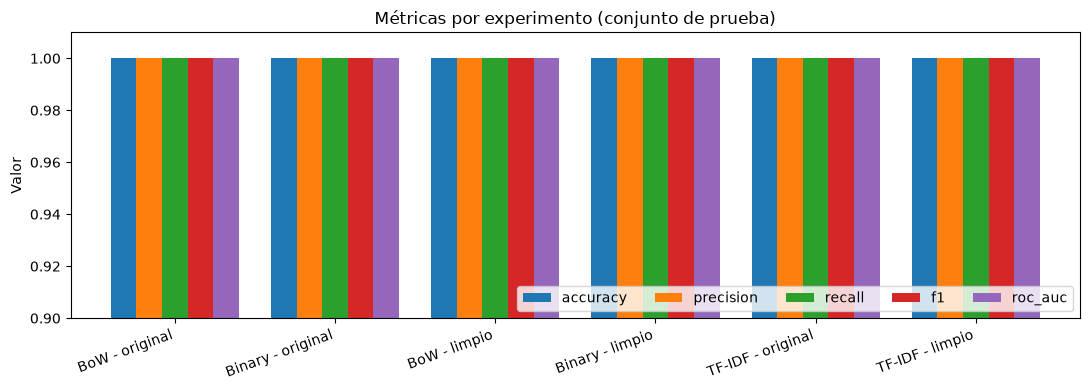

In [69]:
# TODO:
# Grafique accuracy, precision, recall, f1 y roc_auc para cada experimento.

ax = results_df[metricas].plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_title("Métricas por experimento (conjunto de prueba)")
ax.set_xlabel("")
ax.set_ylabel("Valor")
ax.set_ylim(0.9, 1.01)
ax.legend(loc="lower right", ncol=5)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 6.1 Experimento complementario: entrenamiento con pocos datos

Con el conjunto de entrenamiento completo, los seis experimentos obtienen 1,0 en todas las métricas, así que la tabla anterior no permite decidir cuál es mejor. Para diferenciarlos se hace el problema más difícil: cada modelo se entrena con solo 40 reseñas (20 por clase) y se evalúa en el mismo conjunto de prueba. Se repite con 30 muestras distintas y se promedia, para que el resultado no dependa de qué reseñas tocaron.

,f1_40_reseñas,roc_auc_40_reseñas
experiment,,
TF-IDF - original,0.976,0.998
Binary - original,0.972,0.999
BoW - original,0.959,0.997
TF-IDF - limpio,0.956,0.996
Binary - limpio,0.925,0.989
BoW - limpio,0.925,0.989


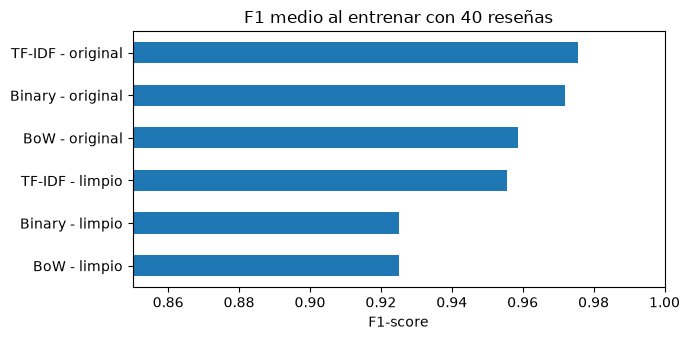

In [70]:
# Entrenamiento con 40 reseñas (20 por clase), promediado sobre 30 muestras
N_MUESTRAS, N_POR_CLASE = 30, 20

crear_vectorizador = {
    "Binary": lambda: CountVectorizer(binary=True, max_features=5000),
    "BoW": lambda: CountVectorizer(binary=False, max_features=5000),
    "TF-IDF": lambda: TfidfVectorizer(max_features=5000),
}
textos = {"original": (X_raw_train, X_raw_test), "limpio": (X_clean_train, X_clean_test)}

filas = []
for semilla in range(N_MUESTRAS):
    idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
    for nombre_vec, crear in crear_vectorizador.items():
        for nombre_txt, (X_tr, X_te) in textos.items():
            r = train_and_evaluate(crear(), X_tr.loc[idx], X_te, y_train.loc[idx], y_test,
                                   f"{nombre_vec} - {nombre_txt}")
            filas.append({"experiment": r["experiment"], "f1": r["f1"], "roc_auc": r["roc_auc"]})

robust_df = (pd.DataFrame(filas).groupby("experiment")[["f1", "roc_auc"]].mean()
             .add_suffix("_40_reseñas")
             .sort_values("f1_40_reseñas", ascending=False))
display(robust_df.round(3))

ax = robust_df["f1_40_reseñas"].sort_values().plot(kind="barh", figsize=(7, 3.5), xlim=(0.85, 1.0))
ax.set_title("F1 medio al entrenar con 40 reseñas")
ax.set_xlabel("F1-score")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [71]:
# TODO:
# Identifique el mejor experimento según F1-score.

mejor_f1 = results_df["f1"].max()
empatados = results_df.index[results_df["f1"] == mejor_f1].tolist()
print(f"F1 más alto: {mejor_f1:.4f}")
print(f"Experimentos con ese F1 ({len(empatados)}): {empatados}")

# Si hay empate, se desempata con el F1 medio al entrenar con pocos datos.
# Solo compiten los modelos de texto limpio: los de texto original se apoyan en las
# plantillas {element}, que delatan la clase negativa (fuga de información).
candidatos = [e for e in empatados if e.endswith("limpio")]
best_name = robust_df.loc[candidatos, "f1_40_reseñas"].idxmax()
best_experiment = next(r for r in resultados if r["experiment"] == best_name)

print(f"\nMejor experimento: {best_name}")
results_df.join(robust_df).loc[[best_name]].round(4)

F1 más alto: 1.0000
Experimentos con ese F1 (6): ['BoW - original', 'Binary - original', 'BoW - limpio', 'Binary - limpio', 'TF-IDF - original', 'TF-IDF - limpio']

Mejor experimento: TF-IDF - original


,accuracy,precision,recall,f1,roc_auc,n_features,log_loss,f1_40_reseñas,roc_auc_40_reseñas
experiment,,,,,,,,,
TF-IDF - original,1.0,1.0,1.0,1.0,1.0,358,0.0611,0.9756,0.9983


## Ejercicio 6

1. ¿Cuál fue el mejor método según F1-score?

   **Respuesta:** Ninguno gana: los seis experimentos tienen un F1 de 1,0 en el conjunto de prueba. Para desempatar entrené cada modelo con solo 40 reseñas. Ahí los modelos con texto original quedan arriba (TF-IDF llega a 0,976), pero lo logran apoyándose en las plantillas `{element}`, así que no los considero. Entre los de texto limpio el mejor es TF-IDF, con un F1 medio de 0,956, y ese es el que tomo como mejor experimento.

In [ ]:
# Pregunta 1: F1 con datos completos y con pocos datos
results_df[["f1"]].join(robust_df[["f1_40_reseñas"]]).sort_values("f1_40_reseñas", ascending=False).round(3)

2. ¿Cuál fue el mejor método según ROC-AUC?

   **Respuesta:** También hay empate: todos tienen ROC-AUC de 1,0. Con pocos datos siguen casi iguales, entre 0,989 y 0,999, con Binary y TF-IDF sobre texto original arriba. Es decir, todos los modelos ordenan bien las reseñas; lo que cambia un poco es dónde ponen el corte entre positivas y negativas.

In [ ]:
# Pregunta 2: ROC-AUC con datos completos y con pocos datos
results_df[["roc_auc"]].join(robust_df[["roc_auc_40_reseñas"]]).sort_values("roc_auc_40_reseñas", ascending=False).round(3)

3. ¿La limpieza mejoró todos los modelos?

   **Respuesta:** No, no mejoró ninguno. Con todos los datos no había margen, porque ya estaban en 1,0. Con pocos datos los tres bajan al usar texto limpio: Binary de 0,972 a 0,925, BoW de 0,959 a 0,925 y TF-IDF de 0,976 a 0,956. La razón no es que limpiar sea malo, sino que la limpieza quita las plantillas `{element}`, que solo aparecen en reseñas negativas y le daban al modelo una pista muy fácil. TF-IDF es el que menos pierde.

In [ ]:
# Pregunta 3: efecto de la limpieza en cada representación (F1 medio con 40 reseñas)
efecto = robust_df["f1_40_reseñas"].rename_axis("experiment").reset_index()
efecto[["representacion", "texto"]] = efecto["experiment"].str.split(" - ", expand=True)
efecto = efecto.pivot(index="representacion", columns="texto", values="f1_40_reseñas")[["original", "limpio"]]
efecto["diferencia"] = efecto["limpio"] - efecto["original"]
efecto.round(3)

4. ¿Qué modelo escogería para producción y por qué?

   **Respuesta:** TF-IDF con texto limpio. Aunque los modelos con texto original puntúan un poco más, lo hacen apoyándose en las plantillas, que son un defecto de este dataset y no existirían en reseñas reales. Entre los modelos con texto limpio, TF-IDF es el mejor cuando hay pocos datos (0,956 contra 0,925 de los otros dos) y además les baja el peso a palabras comunes como `movie`. Antes de usarlo en producción lo probaría con reseñas reales, porque un 100 % en un dataset sintético no garantiza el mismo resultado afuera.

In [ ]:
# Pregunta 4: comparación de los modelos entrenados con texto limpio
limpios = [e for e in results_df.index if e.endswith("limpio")]
results_df.join(robust_df).loc[limpios, ["f1", "roc_auc", "n_features", "log_loss", "f1_40_reseñas"]].sort_values("f1_40_reseñas", ascending=False).round(4)

# 7. Interpretación del modelo

Una ventaja de Logistic Regression con representaciones clásicas es que podemos inspeccionar los coeficientes.

En clasificación binaria:

- Coeficientes positivos altos empujan hacia la clase positiva.
- Coeficientes negativos bajos empujan hacia la clase negativa.

Esto permite responder:

> ¿Qué palabras aprendió el modelo como señales de sentimiento positivo o negativo?

In [ ]:
# TODO:
# Usando el mejor modelo:
# - Obtenga los nombres de las features.
# - Obtenga los coeficientes de Logistic Regression.
# - Muestre las 20 palabras más positivas y 20 más negativas.

print("Modelo analizado:", best_experiment["experiment"])

# Nombres de las features (palabras) y coeficiente de cada una, en el mismo orden
feature_names = best_experiment["vectorizer"].get_feature_names_out()
coefs = best_experiment["model"].coef_[0]

coef_df = pd.DataFrame({"palabra": feature_names, "coeficiente": coefs}).sort_values("coeficiente")
top_neg = coef_df.head(20)             # coeficientes más bajos: empujan hacia la clase negativa
top_pos = coef_df.tail(20).iloc[::-1]  # coeficientes más altos: empujan hacia la clase positiva

pd.DataFrame({
    "positiva": top_pos["palabra"].values,
    "coef_pos": top_pos["coeficiente"].round(2).values,
    "negativa": top_neg["palabra"].values,
    "coef_neg": top_neg["coeficiente"].round(2).values,
}, index=range(1, 21))

In [ ]:
# TODO:
# Grafique las palabras positivas y negativas más importantes.

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].barh(top_neg["palabra"], top_neg["coeficiente"], color="tab:red")
axes[0].invert_yaxis()
axes[0].set_title("20 palabras más negativas")
axes[0].set_xlabel("Coeficiente")

axes[1].barh(top_pos["palabra"], top_pos["coeficiente"], color="tab:green")
axes[1].invert_yaxis()
axes[1].set_title("20 palabras más positivas")
axes[1].set_xlabel("Coeficiente")

fig.suptitle(f"Palabras más importantes del modelo: {best_experiment['experiment']}")
plt.tight_layout()
plt.show()

## Ejercicio 7

1. Revise las 20 palabras más positivas.

   **Respuesta:** Casi todas son adjetivos de elogio: `outstanding`, `exceptional`, `brilliant`, `incredible`, `remarkable`, `compelling`, `powerful`, `excellent`, `stunning`, `beautiful`. El resto viene de frases típicas de las reseñas positivas, como `kept` y `engaged` (*"kept me engaged"*), `end` y `beginning`, o `exceeded expectations`. La única rara es `did`.

2. Revise las 20 palabras más negativas.

   **Respuesta:** También predominan los adjetivos, ahora negativos: `terrible`, `awful`, `miserable`, `boring`, `disappointing`, `abysmal`, `predictable`, `poor`, `dreadful`, `overrated`. Junto a ellos están `waste` y `failed`, y las negaciones `never` y `no`, que aparecen en la lista porque la limpieza las conservó. Las que desentonan son `movie`, `complete` y `sense`.

3. ¿Todas tienen sentido semántico?

   **Respuesta:** La gran mayoría sí. Las excepciones son palabras que solas no dicen nada, pero que en este dataset aparecen siempre dentro de la misma frase: `complete` viene de *"complete disaster"* y *"complete waste of time"*, `sense` de *"made no sense"*, y `kept`, `end` y `beginning` de frases de elogio. El modelo aprende la coincidencia, no el significado.

In [ ]:
# Pregunta 3: palabras con mucho peso que por sí solas no expresan sentimiento
coef_mejor = coef_df.set_index("palabra")["coeficiente"]

for palabra in ["complete", "sense", "kept", "end", "beginning"]:
    idx = X_clean_train[X_clean_train.str.contains(rf"\b{palabra}\b")].index[0]
    print(f"{palabra} ({coef_mejor[palabra]:+.2f}): {df.loc[idx, TEXT_COL]}")

4. ¿Encuentra alguna palabra inesperada?

   **Respuesta:** Sí, tres:

   - `movie` es la tercera más negativa (−2,24), aunque es una palabra neutra. Pasa porque en este dataset sale más veces en las reseñas negativas.
   - `did` cuenta como positiva (+1,47). Viene de *"I didn't want it to end"*, que al limpiar queda como `did not want end`.
   - `not` casi no pesa (+0,13), cuando uno esperaría que fuera negativa. Aparece tanto en *"not worth watching"* como en *"did not want it to end"*, y los dos usos se compensan.

   Como contraste, en el modelo con texto original la palabra más influyente era `element` (−4,76), una plantilla que ni siquiera es parte real de una reseña. Con el texto limpio ese problema desaparece.

In [ ]:
# Pregunta 4: palabras inesperadas en el mejor modelo, comparadas con el modelo de texto original
coef_original = pd.Series(tfidf_raw_result["model"].coef_[0],
                          index=tfidf_raw_result["vectorizer"].get_feature_names_out())

palabras = ["movie", "did", "not", "no", "never", "element", "component", "aspect"]
display(pd.DataFrame({
    best_experiment["experiment"]: coef_mejor.reindex(palabras),
    "TF-IDF - original": coef_original.reindex(palabras),
}).round(2))

print("Más negativas con texto original:", coef_original.sort_values().head(5).index.tolist())
print("Más negativas con texto limpio:  ", coef_mejor.sort_values().head(5).index.tolist())

5. ¿Qué nos dice esto sobre la interpretabilidad de modelos clásicos?

   **Respuesta:** Que son fáciles de revisar: basta mirar los coeficientes para saber en qué se fija el modelo. Aquí eso sirvió para comprobar que el modelo limpio se guía por palabras de sentimiento, y para ver que el de texto original dependía de las plantillas, algo que el 100 % de accuracy no dejaba notar. El límite es que los coeficientes reflejan qué palabras coinciden con cada clase en estos datos, no lo que significan; por eso `movie` o `did` terminan con peso. Hay que leerlos con criterio y no confiar solo en la métrica.

# 8. Análisis de errores

Las métricas agregadas son importantes, pero no son suficientes.

Un buen análisis de NLP debe revisar ejemplos concretos donde el modelo falla:

- Falsos positivos: reviews negativas clasificadas como positivas.
- Falsos negativos: reviews positivas clasificadas como negativas.
- Casos ambiguos.
- Textos con sarcasmo.
- Textos con negaciones.
- Textos demasiado cortos o demasiado largos.

Este análisis es clave para mejorar el pipeline.

In [ ]:
# TODO:
# Construya un DataFrame con:
# - texto original
# - texto limpio
# - etiqueta real
# - predicción
# - probabilidad de clase positiva
# - tipo de error

print("Modelo analizado:", best_experiment["experiment"])

errors_df = pd.DataFrame({
    "texto_original": X_raw_test,
    "texto_limpio": X_clean_test,
    "etiqueta_real": y_test,
    "prediccion": best_experiment["y_pred"],
    "prob_positiva": best_experiment["y_proba"],
})

# Falso positivo: era negativa (0) y se predijo positiva (1). Falso negativo: lo contrario.
errors_df["tipo_error"] = np.select(
    [(errors_df["etiqueta_real"] == 0) & (errors_df["prediccion"] == 1),
     (errors_df["etiqueta_real"] == 1) & (errors_df["prediccion"] == 0)],
    ["Falso positivo", "Falso negativo"],
    default="Correcto",
)

print(errors_df["tipo_error"].value_counts().to_string())
errors_df.head()

In [ ]:
# TODO:
# Muestre ejemplos de falsos positivos y falsos negativos.

for tipo in ["Falso positivo", "Falso negativo"]:
    tabla = errors_df[errors_df["tipo_error"] == tipo]
    print(f"{tipo.replace('Falso', 'Falsos')}s: {len(tabla)}")
    if tabla.empty:
        print("  No hay ninguno: el modelo acierta todas las reseñas de prueba.\n")
    for _, fila in tabla.head(5).iterrows():
        print(f"  [{fila['prob_positiva']:.2f}] {fila['texto_original']}")
        print(f"         limpio: {fila['texto_limpio']}\n")

In [ ]:
# TODO:
# Encuentre predicciones de baja confianza.
# Pista: probabilidad cercana a 0.5.

# Confianza: qué tan lejos está la probabilidad de 0.5 (0.5 = duda total, 1.0 = seguridad total)
errors_df["confianza"] = np.maximum(errors_df["prob_positiva"], 1 - errors_df["prob_positiva"])

baja_confianza = errors_df.sort_values("confianza").head(10)
display(baja_confianza[["texto_original", "texto_limpio", "etiqueta_real", "prediccion", "prob_positiva"]].round(3))

dudosas = errors_df["prob_positiva"].between(0.2, 0.8).sum()
print(f"Predicciones con probabilidad entre 0.2 y 0.8: {dudosas} de {len(errors_df)}")
print(f"Confianza mínima: {errors_df['confianza'].min():.3f}")

plt.figure(figsize=(8, 4))
for valor, nombre in [(1, "positive"), (0, "negative")]:
    plt.hist(errors_df.loc[errors_df["etiqueta_real"] == valor, "prob_positiva"],
             bins=np.linspace(0, 1, 41), alpha=0.5, label=nombre)
plt.axvline(0.5, color="gray", linestyle="--")
plt.title("Probabilidad de clase positiva por clase real")
plt.xlabel("Probabilidad de clase positiva")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

## 8.1 Análisis complementario: errores al entrenar con pocos datos

El mejor modelo acierta las 400 reseñas de prueba, así que no tiene falsos positivos ni falsos negativos que revisar. Para poder estudiar en qué tipo de reseñas falla, se repite el experimento de la sección 6.1: se entrena el mismo modelo (TF-IDF con texto limpio) con solo 40 reseñas, 30 veces, y se cuenta cuántas veces se equivoca en cada reseña de prueba.

In [ ]:
# Errores del mejor tipo de modelo al entrenar con 40 reseñas, acumulados en 30 muestras
veces_fp = np.zeros(len(y_test), dtype=int)
veces_fn = np.zeros(len(y_test), dtype=int)

for semilla in range(N_MUESTRAS):
    idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
    r = train_and_evaluate(TfidfVectorizer(max_features=5000),
                           X_clean_train.loc[idx], X_clean_test, y_train.loc[idx], y_test, "pocos datos")
    veces_fp += (r["y_pred"] == 1) & (y_test.values == 0)
    veces_fn += (r["y_pred"] == 0) & (y_test.values == 1)

stress_df = errors_df[["texto_original", "texto_limpio", "etiqueta_real"]].assign(veces_fp=veces_fp, veces_fn=veces_fn)

total = N_MUESTRAS * len(y_test)
print(f"Falsos positivos: {veces_fp.sum()} | Falsos negativos: {veces_fn.sum()} (de {total:,} predicciones)")
print(f"Reseñas distintas con algún error: {(veces_fp > 0).sum()} como falso positivo, {(veces_fn > 0).sum()} como falso negativo")

for titulo, columna in [("FALSOS POSITIVOS", "veces_fp"), ("FALSOS NEGATIVOS", "veces_fn")]:
    print(f"\n{titulo} más repetidos (veces que falló, de {N_MUESTRAS} modelos):")
    for _, fila in stress_df.sort_values(columna, ascending=False, kind="stable").head(5).iterrows():
        print(f"  [{fila[columna]}] {fila['texto_original']}")
        print(f"        limpio: {fila['texto_limpio']}")

## Ejercicio 8

1. Revise 5 falsos positivos.

   **Respuesta:** El mejor modelo no tiene ninguno: acierta todas las reseñas de prueba. Los que revisé salen de entrenarlo con solo 40 reseñas (sección 8.1). Los cinco más repetidos son la misma frase, que solo cambia un sustantivo: *"Atrocious {element} and deplorable {aspect}. This is a stinker that fails on every level"* (y lo mismo con `washout`, `insult` o `mess`). Después de limpiar quedan en cinco palabras, como `atrocious deplorable stinker fails level`.

2. Revise 5 falsos negativos.

   **Respuesta:** Tampoco hay con el modelo completo. Con pocos datos, los cinco más repetidos también son una sola frase que cambia de sustantivos: *"Beautiful editing and powerful characters. This movie will stay with me for a long time"*. Limpia queda como `beautiful editing powerful characters movie stay long time`.

3. ¿Qué patrones encuentra?

   **Respuesta:** Los errores no están repartidos al azar, se concentran en unas pocas frases. En todas pasa lo mismo: las palabras que llevan el sentimiento (`atrocious`, `deplorable`, `beautiful`, `powerful`) son poco frecuentes, y con 40 reseñas muchas veces el modelo nunca las vio. Entonces decide con lo poco que reconoce; en los falsos negativos eso es `movie` y `time`, que aprendió como negativas. Las predicciones menos seguras del modelo completo son del mismo estilo: reseñas que tras la limpieza quedan muy cortas, como `overrated overhyped movie worn unacceptable`.

4. ¿Los errores parecen deberse a limpieza, representación o ambigüedad del lenguaje?

   **Respuesta:** Sobre todo a la representación, sumada a los pocos datos: cada palabra es una columna independiente, así que una palabra que no estaba en el entrenamiento no aporta nada, y el modelo no sabe que `atrocious` se parece a `terrible`. La limpieza también influye. Con el texto original, la frase de *"…stay with me for a long time"* no falla nunca (0 de 390 predicciones, contra 121 con texto limpio), porque stop words como `me`, `will` y `for` le servían de pista; y la de *"Atrocious…"* falla menos (81 contra 125 de 510) gracias a `{element}`. Ambigüedad del lenguaje no es: son reseñas muy claras para cualquier persona, sin sarcasmo ni doble sentido.

In [ ]:
# Pregunta 4: errores en las dos frases problemáticas, con texto limpio y con texto original
frases = {
    "Atrocious ... fails on every level (negativa)": X_raw_test.str.startswith("Atrocious").values,
    "... will stay with me for a long time (positiva)": X_raw_test.str.contains("stay with me").values,
}

filas = []
for nombre_txt, X_tr, X_te in [("limpio", X_clean_train, X_clean_test), ("original", X_raw_train, X_raw_test)]:
    errores = np.zeros(len(y_test), dtype=int)
    for semilla in range(N_MUESTRAS):
        idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
        r = train_and_evaluate(TfidfVectorizer(max_features=5000), X_tr.loc[idx], X_te, y_train.loc[idx], y_test, "pocos datos")
        errores += r["y_pred"] != y_test.values
    for frase, mascara in frases.items():
        filas.append({"frase": frase, "texto": nombre_txt, "errores": errores[mascara].sum()})

tabla = pd.DataFrame(filas).pivot(index="frase", columns="texto", values="errores")[["limpio", "original"]]
tabla["predicciones"] = [frases[f].sum() * N_MUESTRAS for f in tabla.index]
tabla

5. Proponga una mejora al pipeline.

   **Respuesta:** Primero probé dos cambios sencillos sobre el mismo experimento: agregar bigramas y quitar `movie` y `film` como stop words del dominio. Ninguno ayudó de verdad: el F1 medio pasó de 0,956 a 0,957 con bigramas y bajó a 0,946 al quitar `movie` y `film`. Tiene sentido, porque el problema no es el orden de las palabras sino que el modelo no conoce algunas. Por eso propongo otra mejora: usar una representación que relacione palabras parecidas, como embeddings, para que `atrocious` aproveche lo aprendido con `terrible`. Y, si se puede, entrenar con más datos y más variados, que es justo lo que hace desaparecer estos errores cuando se usan las 1.600 reseñas.

In [ ]:
# Pregunta 5: mejoras sencillas probadas sobre el mismo experimento de pocos datos (texto limpio)
variantes = {
    "TF-IDF (actual)": lambda: TfidfVectorizer(max_features=5000),
    "TF-IDF + bigramas": lambda: TfidfVectorizer(max_features=5000, ngram_range=(1, 2)),
    "TF-IDF sin 'movie' ni 'film'": lambda: TfidfVectorizer(max_features=5000, stop_words=["movie", "film"]),
}

f1_variantes = {nombre: [] for nombre in variantes}
for semilla in range(N_MUESTRAS):
    idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
    for nombre, crear in variantes.items():
        r = train_and_evaluate(crear(), X_clean_train.loc[idx], X_clean_test, y_train.loc[idx], y_test, nombre)
        f1_variantes[nombre].append(r["f1"])

pd.DataFrame({"f1_medio_40_reseñas": {n: np.mean(v) for n, v in f1_variantes.items()}}).round(3)

# 9. Conclusiones y próximos pasos

En este notebook construimos un pipeline completo de análisis de sentimiento usando técnicas clásicas de NLP.

## Lo aprendido

1. La exploración textual permite entender longitud, vocabulario, ruido y diferencias entre clases.
2. La limpieza textual puede ayudar, pero también puede eliminar información útil.
3. Binary Encoding representa presencia/ausencia de palabras.
4. Bag of Words conserva frecuencia.
5. TF-IDF pondera la importancia relativa de cada palabra.
6. Logistic Regression es un modelo fuerte, simple e interpretable para clasificación de texto clásica.
7. Las métricas deben complementarse con análisis de errores.
8. La interpretación de coeficientes ayuda a entender qué aprendió el modelo.

## Limitaciones de los métodos clásicos

Estos métodos no capturan bien:

- Orden de palabras.
- Sarcasmo.
- Contexto largo.
- Significado profundo.
- Relaciones semánticas.
- Ambigüedad lingüística.

## Próximos pasos recomendados

Para continuar la clase o el proyecto, se puede explorar:

- N-gramas.
- Comparación entre stop words con y sin negaciones.
- Lemmatization con spaCy.
- Word embeddings.
- Modelos basados en transformers.
- Fine-tuning de BERT para análisis de sentimiento.

## Ejercicio final

Construya una conclusión ejecutiva de máximo 10 líneas respondiendo:

1. ¿Cuál fue el mejor modelo?
2. ¿Qué representación textual funcionó mejor?
3. ¿La limpieza ayudó?
4. ¿Qué limitaciones observó?
5. ¿Qué recomendaría como siguiente experimento?

**Conclusión ejecutiva:**

1. **Mejor modelo:** Logistic Regression con TF-IDF sobre texto limpio. Los seis experimentos llegan a 1,0 en prueba, así que lo elegí por ser el más sólido entre los que no dependen de las plantillas del dataset.
2. **Representación:** con todos los datos, Binary, BoW y TF-IDF empatan. La diferencia aparece al entrenar con solo 40 reseñas, donde TF-IDF saca ventaja (F1 de 0,956 contra 0,925).
3. **Limpieza:** no subió las métricas, pero sí ayudó: eliminó las plantillas `{element}`, que estaban en el 94 % de las reseñas negativas y delataban la etiqueta, y redujo el vocabulario en un 15 %.
4. **Limitaciones:** el dataset es sintético y demasiado fácil, así que el 100 % no se puede esperar en reseñas reales. Además el modelo no entiende palabras que no vio ni el contexto: con una reseña escrita de otra forma, como *"I loved it"*, se equivoca.
5. **Siguiente experimento:** probar el pipeline con reseñas reales de IMDb y comparar TF-IDF contra una representación con embeddings.

# Anexo opcional: ideas para extender el notebook

Si se desea convertir este notebook en una práctica más avanzada, se pueden agregar:

1. `ngram_range=(1,2)` para incluir bigramas como `not good`.
2. Comparación entre remover y conservar negaciones.
3. Validación cruzada.
4. Búsqueda de hiperparámetros con `GridSearchCV`.
5. Exportación del mejor modelo con `joblib`.
6. Construcción de una función `predict_sentiment(text)`.

## A.1 Bigramas con `ngram_range=(1, 2)`

Se entrena el mejor modelo agregando bigramas. El F1 sigue en 1,0, pero el vocabulario pasa de 303 a 2.285 features. Lo interesante está en los coeficientes: el modelo ahora distingue `not worth` (negativo) de `not want` (positivo, de *"did not want it to end"*), algo que con la palabra `not` suelta no podía hacer.

In [ ]:
# A.1 TF-IDF con unigramas y bigramas sobre texto limpio
bigram_result = train_and_evaluate(
    TfidfVectorizer(max_features=5000, ngram_range=(1, 2)),
    X_clean_train, X_clean_test, y_train, y_test,
    "TF-IDF - limpio + bigramas",
)
print(f"F1: {bigram_result['f1']:.3f} | features: {bigram_result['n_features']} (sin bigramas: {best_experiment['n_features']})")

# Coeficientes de las negaciones, solas y dentro de bigramas
coef_bigramas = pd.Series(bigram_result["model"].coef_[0],
                          index=bigram_result["vectorizer"].get_feature_names_out())
es_negacion = coef_bigramas.index.str.match(r"^(?:not|no|never)(?: |$)")
coef_bigramas[es_negacion].sort_values().round(2)

## A.2 Remover o conservar negaciones

Se compara el texto limpio actual, que conserva `not`, `no` y `never`, con una versión que también las elimina. En este dataset no cambia nada: los dos llegan a F1 de 1,0, y con 40 reseñas quedan en 0,956 y 0,958. Solo unas 270 reseñas tienen negaciones y sus otras palabras ya bastan para clasificarlas. En reseñas reales, donde abundan frases como *"not good"*, sí se esperaría diferencia.

In [ ]:
# A.2 Mismo modelo con y sin negaciones en el texto limpio
def quitar_negaciones(textos):
    return textos.apply(lambda t: " ".join(w for w in t.split() if w not in ENGLISH_STOP_WORDS))

X_sin_neg_train, X_sin_neg_test = quitar_negaciones(X_clean_train), quitar_negaciones(X_clean_test)

filas = []
for nombre, X_tr, X_te in [("Conserva negaciones", X_clean_train, X_clean_test),
                           ("Remueve negaciones", X_sin_neg_train, X_sin_neg_test)]:
    completo = train_and_evaluate(TfidfVectorizer(max_features=5000), X_tr, X_te, y_train, y_test, nombre)
    f1_pocos = []
    for semilla in range(N_MUESTRAS):
        idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
        f1_pocos.append(train_and_evaluate(TfidfVectorizer(max_features=5000),
                                           X_tr.loc[idx], X_te, y_train.loc[idx], y_test, nombre)["f1"])
    filas.append({"texto": nombre, "f1": completo["f1"], "n_features": completo["n_features"],
                  "f1_40_reseñas": np.mean(f1_pocos)})
pd.DataFrame(filas).set_index("texto").round(3)

## A.3 Validación cruzada

En lugar de una sola división, el conjunto de entrenamiento se parte en 5 y el modelo se evalúa 5 veces, cada vez con una parte distinta como validación. El vectorizador va dentro de un `Pipeline` para que aprenda el vocabulario solo con los datos de entrenamiento de cada partición. El resultado es 1,0 en las cinco, lo que confirma que el 100 % no fue suerte de la división original.

In [ ]:
# A.3 Validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for metrica in ["accuracy", "f1", "roc_auc"]:
    scores = cross_val_score(pipeline, X_clean_train, y_train, cv=cv, scoring=metrica)
    print(f"{metrica:9}: {scores.round(3)} | media = {scores.mean():.3f}")

## A.4 Búsqueda de hiperparámetros con `GridSearchCV`

Se prueban 8 combinaciones: con y sin bigramas, y cuatro valores de `C` (la regularización de Logistic Regression). Todas obtienen F1 de 1,0, así que por F1 la búsqueda no puede elegir. Para desempatar se usa el log loss, que mide qué tan seguras son las probabilidades.

In [ ]:
# A.4 GridSearchCV sobre el pipeline, con F1 y log loss como métricas
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.01, 0.1, 1, 10],
}
grid = GridSearchCV(pipeline, param_grid, cv=cv,
                    scoring={"f1": "f1", "log_loss": "neg_log_loss"}, refit="log_loss")
grid.fit(X_clean_train, y_train)

cv_df = pd.DataFrame(grid.cv_results_)[["param_tfidf__ngram_range", "param_clf__C", "mean_test_f1", "mean_test_log_loss"]]
cv_df["mean_test_log_loss"] = -cv_df["mean_test_log_loss"]  # scikit-learn lo guarda con signo negativo
display(cv_df.sort_values("mean_test_log_loss").round(4))

print("Mejor combinación según log loss:", grid.best_params_)
print(f"F1 en prueba con esa combinación: {f1_score(y_test, grid.predict(X_clean_test)):.3f}")

## A.5 Exportación del mejor modelo con `joblib`

Se guarda en un archivo el pipeline completo (vectorizador y modelo) del mejor experimento, para poder usarlo después sin volver a entrenar. Se comprueba que el modelo cargado da las mismas predicciones. El archivo espera texto ya limpio: quien lo use debe aplicar antes `clean_text`.

In [ ]:
# A.5 Guardar y volver a cargar el mejor modelo (TF-IDF con texto limpio)
import joblib

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_clean_train, y_train)

MODEL_PATH = "sentiment_model.joblib"
joblib.dump(final_model, MODEL_PATH)
print(f"Modelo guardado en {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024:.1f} KB)")

modelo_cargado = joblib.load(MODEL_PATH)
iguales = (modelo_cargado.predict(X_clean_test) == best_experiment["y_pred"]).all()
print("¿El modelo cargado predice igual que el mejor experimento?", iguales)

## A.6 Función `predict_sentiment(text)`

La función limpia el texto, lo vectoriza con el mejor modelo y devuelve el sentimiento con su probabilidad. También informa cuántas palabras del texto reconoce el modelo, porque ahí está su límite: acierta con reseñas parecidas a las del dataset, pero con frases escritas de otra forma reconoce pocas palabras y se equivoca. *"I loved it, one of the best films of the year!"* sale como negativa, y *"It was fine"* no tiene ninguna palabra conocida, así que la respuesta depende solo del sesgo del modelo.

In [ ]:
# TODO OPCIONAL:
# Construya una función predict_sentiment(text) usando el mejor modelo.

def predict_sentiment(text):
    texto_limpio = clean_text(text)
    X = best_experiment["vectorizer"].transform([texto_limpio])
    prob_positiva = best_experiment["model"].predict_proba(X)[0, 1]
    return {
        "sentimiento": "positive" if prob_positiva >= 0.5 else "negative",
        "prob_positiva": round(float(prob_positiva), 3),
        "palabras_reconocidas": int(X.nnz),  # palabras del texto que están en el vocabulario del modelo
        "texto_limpio": texto_limpio,
    }

ejemplos = [
    "Brilliant screenplay and outstanding acting. A true masterpiece.",
    "Terrible plot and awful dialogue. A complete waste of time.",
    "This movie was not good at all.",
    "I loved it, one of the best films of the year!",
    "It was fine.",
]
pd.DataFrame([predict_sentiment(t) for t in ejemplos], index=ejemplos)